# 신약 후보물질 독성 예측 EDA

분자 구조와 특성으로 독성 여부를 예측하는 데이터의 첫 점검. 원본: `Data/input_data/train.csv`.

**label: 0 = 독성 있음, 1 = 독성 없음.** 독성 없음은 해당 실험의 판정 결과이며 모든 조건에서의 안전성을 의미하지 않음.

```text
분자 → SMILES(구조 문자열) → Fingerprint(구조를 숫자로 표현)
                                  + 분자 특성 4개
                                         ↓
                                    독성 여부 예측
```

숫자 입력 3,076개 = Fingerprint 3,072개 + 분자 특성 4개. 정답을 포함한 전체 컬럼은 3,078개.

필요 패키지: `pandas`, `numpy`, `matplotlib`, `rdkit`. 프로젝트 루트에서 위부터 실행.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from matplotlib import font_manager
from rdkit import Chem, RDLogger

RDLogger.DisableLog('rdApp.*')
plt.rcParams.update({'figure.figsize': (9, 4), 'font.size': 11,
                     'axes.spines.top': False, 'axes.spines.right': False})
# 그래프 셀을 따로 실행해도 한글 글꼴 적용
from pathlib import Path as _FontPath
from matplotlib import font_manager as _font_manager
_font_path = _FontPath('/System/Library/Fonts/Supplemental/AppleGothic.ttf')
if _font_path.is_file():
    _font_manager.fontManager.addfont(str(_font_path))
    plt.rcParams['font.family'] = _font_manager.FontProperties(fname=str(_font_path)).get_name()
else:
    _korean_fonts = [f for f in ['NanumGothic', 'Nanum Gothic', 'Malgun Gothic', 'AppleGothic']
                     if f in _font_manager.get_font_names()]
    if not _korean_fonts:
        raise RuntimeError('한글 글꼴 설치 후 커널 재시작 필요: NanumGothic 또는 Malgun Gothic')
    plt.rcParams['font.family'] = _korean_fonts[0]
plt.rcParams['axes.unicode_minus'] = False

COLORS = {0: '#C46A31', 1: '#287C8E'}
NAMES = {0: '독성 있음 (0)', 1: '독성 없음 (1)'}
data_path = Path('Data/input_data/train.csv')
df = pd.read_csv(data_path)
properties = ['MolWt', 'clogp', 'sa_score', 'qed']
fp_groups = {name: [c for c in df if c.startswith(name + '_')]
             for name in ['ecfp', 'fcfp', 'ptfp']}
fp_columns = sum(fp_groups.values(), [])
print(f'데이터 크기: {len(df):,}행 × {df.shape[1]:,}개 컬럼')
display(df[['SMILES'] + properties + ['label']].head(3))

데이터 크기: 8,349행 × 3,078개 컬럼


,SMILES,MolWt,clogp,sa_score,qed,label
0,Nc1ccncc1,94.117,0.66380,1.951060,0.512651,1
1,Cc1cc(n[nH]1)C(=O)O,126.115,0.41632,2.373113,0.572518,1
2,NCCCS(=O)(=O)O,139.176,-0.77700,2.336083,0.502646,1


## 1. 결측치와 중복 여부

- **결측치**: 값이 비어 있는 상태. Fingerprint의 0은 정상 값
- **중복**: 같은 데이터 또는 같은 분자의 반복 수록. 구조 중복은 RDKit의 대표 구조 문자열(canonical SMILES)로 비교
- 아래 중복 건수는 각 기준에서 첫 행을 제외한 **추가 행 수**. 기준 간 중복 가능성이 있어 합산 불가

In [2]:
expected = (['SMILES'] + [f'{g}_{i}' for g in fp_groups for i in range(1024)]
            + properties + ['label'])
missing_counts = df.isna().sum()
fp = df[fp_columns]
quality = pd.Series({
    'rows': len(df), 'columns': df.shape[1],
    'missing_cells': int(missing_counts.sum()),
    'columns_with_missing': int((missing_counts > 0).sum()),
    'empty_or_blank_smiles': int(df.SMILES.fillna('').str.strip().eq('').sum()),
    'exact_duplicate_extra_rows': int(df.duplicated().sum()),
    'duplicate_smiles_extra_rows': int(df.SMILES.duplicated().sum()),
    'invalid_label_cells': int((~df.label.isin([0, 1])).sum()),
    'invalid_fingerprint_cells': int((~fp.isin([0, 1])).sum().sum()),
    'nonfinite_property_cells': int((~np.isfinite(df[properties].to_numpy())).sum()),
}, name='count')
assert set(df.columns) == set(expected), '데이터 컬럼 명세 확인 필요'
assert quality['invalid_label_cells'] == 0
assert quality['invalid_fingerprint_cells'] == 0
assert quality['nonfinite_property_cells'] == 0

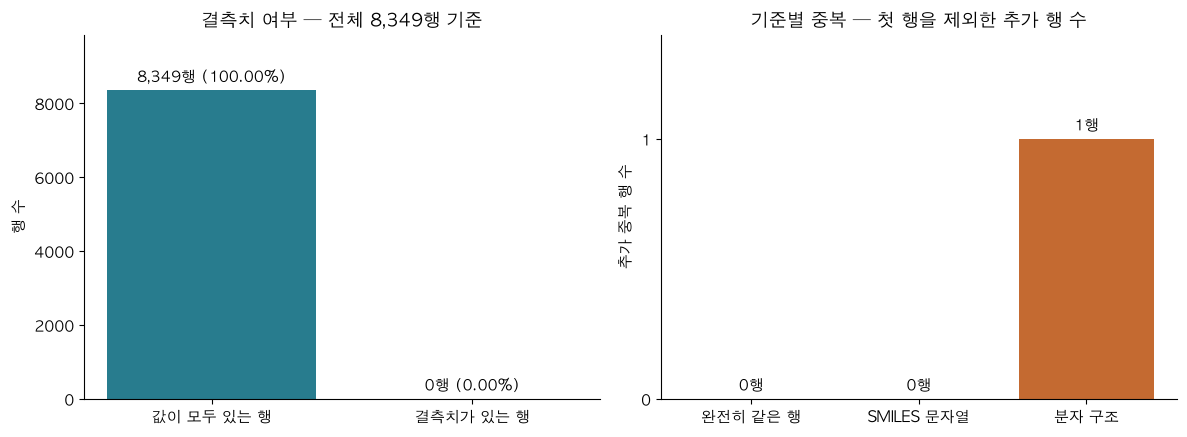

전체 결측 셀: 0개
구조 중복 그룹: 1개 / 해당 행: 2개
구조 파싱 실패: 0개 / 동일 구조의 정답 충돌: 0개


In [3]:
# 그래프 셀을 따로 실행해도 한글 글꼴 적용
from pathlib import Path as _FontPath
from matplotlib import font_manager as _font_manager
_font_path = _FontPath('/System/Library/Fonts/Supplemental/AppleGothic.ttf')
if _font_path.is_file():
    _font_manager.fontManager.addfont(str(_font_path))
    plt.rcParams['font.family'] = _font_manager.FontProperties(fname=str(_font_path)).get_name()
else:
    _korean_fonts = [f for f in ['NanumGothic', 'Nanum Gothic', 'Malgun Gothic', 'AppleGothic']
                     if f in _font_manager.get_font_names()]
    if not _korean_fonts:
        raise RuntimeError('한글 글꼴 설치 후 커널 재시작 필요: NanumGothic 또는 Malgun Gothic')
    plt.rcParams['font.family'] = _korean_fonts[0]
plt.rcParams['axes.unicode_minus'] = False

def canonicalize(value):
    mol = Chem.MolFromSmiles(value) if isinstance(value, str) else None
    return Chem.MolToSmiles(mol, isomericSmiles=True) if mol is not None else None

canonical = df.SMILES.map(canonicalize)
molecule_labels = pd.DataFrame({'canonical': canonical, 'label': df.label})
valid = molecule_labels.dropna(subset=['canonical'])
counts = valid.groupby('canonical').size()
label_counts = valid.groupby('canonical').label.nunique()
conflict_keys = label_counts[label_counts > 1].index
structure_quality = pd.Series({
    'invalid_smiles_rows': int(canonical.isna().sum()),
    'unique_canonical_molecules': int(canonical.nunique()),
    'canonical_duplicate_extra_rows': int(valid.canonical.duplicated().sum()),
    'duplicate_molecule_groups': int((counts > 1).sum()),
    'rows_in_duplicate_molecule_groups': int(counts[counts > 1].sum()),
    'conflicting_label_groups': len(conflict_keys),
    'rows_in_conflicting_groups': int(valid.canonical.isin(conflict_keys).sum()),
}, name='count')
missing_rows = df.isna().any(axis=1)
missing_counts_plot = [int((~missing_rows).sum()), int(missing_rows.sum())]
duplicate_counts_plot = [int(df.duplicated().sum()), int(df.SMILES.duplicated().sum()),
                         int(valid.canonical.duplicated().sum())]
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
ax = axes[0]
bars = ax.bar(['값이 모두 있는 행', '결측치가 있는 행'], missing_counts_plot,
              color=['#287C8E', '#C46A31'])
for bar, count in zip(bars, missing_counts_plot):
    ax.annotate(f'{count:,}행 ({count/len(df):.2%})',
                (bar.get_x()+bar.get_width()/2, count), xytext=(0, 6),
                textcoords='offset points', ha='center')
ax.set(title='결측치 여부 — 전체 8,349행 기준', ylabel='행 수', ylim=(0, len(df)*1.18))
ax = axes[1]
bars = ax.bar(['완전히 같은 행', 'SMILES 문자열', '분자 구조'], duplicate_counts_plot,
              color=['#8D9CA2', '#8D9CA2', '#C46A31'])
for bar, count in zip(bars, duplicate_counts_plot):
    ax.annotate(f'{count}행', (bar.get_x()+bar.get_width()/2, count), xytext=(0, 6),
                textcoords='offset points', ha='center')
ax.set(title='기준별 중복 — 첫 행을 제외한 추가 행 수', ylabel='추가 중복 행 수', ylim=(0, max(duplicate_counts_plot + [1])*1.4))
ax.set_yticks(range(max(duplicate_counts_plot + [1])+1))
fig.tight_layout()
plt.show()
print(f'전체 결측 셀: {int(df.isna().sum().sum()):,}개')
print(f'구조 중복 그룹: {int((counts > 1).sum())}개 / 해당 행: {int(counts[counts > 1].sum())}개')
print(f'구조 파싱 실패: {int(canonical.isna().sum())}개 / 동일 구조의 정답 충돌: {len(conflict_keys)}개')


**쉽게 보면**

- 비어 있는 값은 0개 → 결측치 채우기 불필요
- 완전히 같은 행과 같은 SMILES 문자열은 0개지만, **표현만 다르고 구조가 같은 분자 1쌍 존재**
- 두 행의 정답도 동일 → 검증 시 두 행을 같은 그룹으로 묶거나 중복 정리 검토

구조 중복은 RDKit 기본 설정 기준이며, 염 제거 등 추가적인 구조 표준화는 미수행.

## 2. 독성 데이터 비율

전체 행에서 독성 있음과 없음의 개수 및 비율 비교. 중복 제거 전 기준.

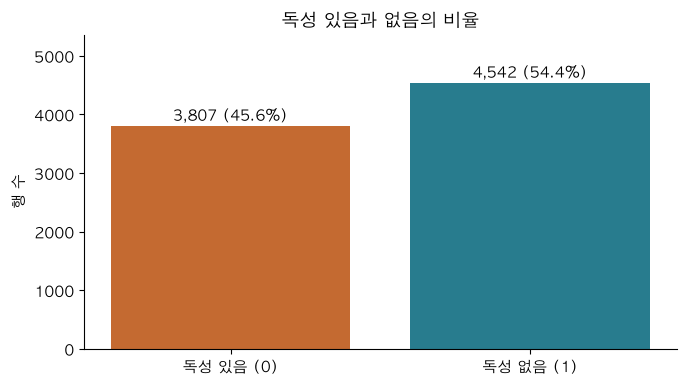

모두 독성 없음으로 예측한 기준 F1: 0.7047


In [4]:
# 그래프 셀을 따로 실행해도 한글 글꼴 적용
from pathlib import Path as _FontPath
from matplotlib import font_manager as _font_manager
_font_path = _FontPath('/System/Library/Fonts/Supplemental/AppleGothic.ttf')
if _font_path.is_file():
    _font_manager.fontManager.addfont(str(_font_path))
    plt.rcParams['font.family'] = _font_manager.FontProperties(fname=str(_font_path)).get_name()
else:
    _korean_fonts = [f for f in ['NanumGothic', 'Nanum Gothic', 'Malgun Gothic', 'AppleGothic']
                     if f in _font_manager.get_font_names()]
    if not _korean_fonts:
        raise RuntimeError('한글 글꼴 설치 후 커널 재시작 필요: NanumGothic 또는 Malgun Gothic')
    plt.rcParams['font.family'] = _korean_fonts[0]
plt.rcParams['axes.unicode_minus'] = False

label_counts = df.label.value_counts().reindex([0, 1], fill_value=0)
label_table = pd.DataFrame({'count': label_counts,
                            'percent': label_counts / len(df) * 100})
label_table.index = [NAMES[i] for i in label_table.index]

majority = int(label_counts.idxmax())
majority_accuracy = label_counts.max() / len(df)
majority_f1 = 2 * label_counts[1] / (len(df) + label_counts[1]) if majority == 1 else 0.0
fig, ax = plt.subplots(figsize=(7, 4))
bars = ax.bar([NAMES[0], NAMES[1]], label_counts.values,
              color=[COLORS[0], COLORS[1]])
for bar, count in zip(bars, label_counts.values):
    ax.text(bar.get_x() + bar.get_width()/2, count,
            f'{count:,} ({count/len(df):.1%})', ha='center', va='bottom')
ax.set(title='독성 있음과 없음의 비율', ylabel='행 수')
ax.set_ylim(0, label_counts.max()*1.18)
fig.tight_layout()
plt.show()
print(f'모두 독성 없음으로 예측한 기준 F1: {majority_f1:.4f}')

**쉽게 보면**

- 독성 있음 **3,807개(45.60%)**, 독성 없음 **4,542개(54.40%)** → 한쪽에 심하게 몰리지 않은 구성
- 현재 클래스 비율만으로 데이터 늘리기나 줄이기부터 적용할 필요는 낮음
- 전부 독성 없음으로 예측해도 F1은 **0.7047** → 이 값과 비교하지 않고 모델이 좋다고 판단하면 오해 가능

**과제 F1**: 독성 없음(1) 기준 정밀도와 재현율의 조화평균. 독성 물질을 놓치지 않는지도 확인하기 위해 **독성 Recall(0)** 별도 확인.

- **정밀도**: 독성 없음으로 예측한 것 중 실제 독성 없는 비율
- **재현율(Recall)**: 해당 실제 클래스 중 모델이 맞게 찾아낸 비율

[F1 정의](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.f1_score.html)

## 3. 어떤 분자 특성이 다른가?

- `MolWt`: 분자량
- `clogp`: 지용성 관련 값. 높을수록 상대적으로 기름 성질의 환경에 잘 분배되는 경향
- `sa_score`: 합성 난이도. 과제 기준 1은 쉬움, 10은 어려움
- `qed`: 약물 유사도. 약효 또는 안전성 보장과 구분

아래 그래프는 같은 구간으로 나눈 **집단별 밀도** 비교. 막대의 높이는 개수가 아닌 분포의 집중 정도.

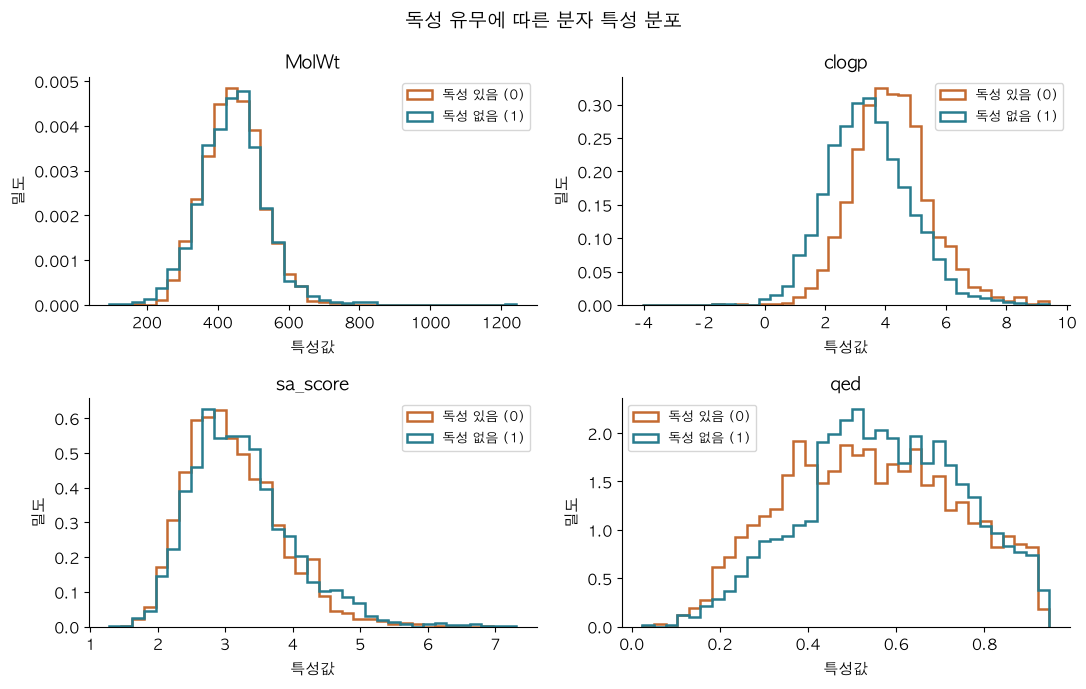

In [5]:
# 그래프 셀을 따로 실행해도 한글 글꼴 적용
from pathlib import Path as _FontPath
from matplotlib import font_manager as _font_manager
_font_path = _FontPath('/System/Library/Fonts/Supplemental/AppleGothic.ttf')
if _font_path.is_file():
    _font_manager.fontManager.addfont(str(_font_path))
    plt.rcParams['font.family'] = _font_manager.FontProperties(fname=str(_font_path)).get_name()
else:
    _korean_fonts = [f for f in ['NanumGothic', 'Nanum Gothic', 'Malgun Gothic', 'AppleGothic']
                     if f in _font_manager.get_font_names()]
    if not _korean_fonts:
        raise RuntimeError('한글 글꼴 설치 후 커널 재시작 필요: NanumGothic 또는 Malgun Gothic')
    plt.rcParams['font.family'] = _korean_fonts[0]
plt.rcParams['axes.unicode_minus'] = False

fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for ax, col in zip(axes.flat, properties):
    edges = np.histogram_bin_edges(df[col].dropna(), bins=35)
    for k in [0, 1]:
        ax.hist(df.loc[df.label.eq(k), col].dropna(), bins=edges,
                density=True, histtype='step', linewidth=1.8,
                label=NAMES[k], color=COLORS[k])
    ax.set(title=col, xlabel='특성값', ylabel='밀도')
    ax.legend(fontsize=9)
fig.suptitle('독성 유무에 따른 분자 특성 분포', fontsize=14)
fig.tight_layout()
plt.show()

**쉽게 보면**

| 특성 | 관찰 결과 | 해석 |
| --- | --- | --- |
| `clogp` | 중앙값: 독성 4.15, 비독성 3.37 | 독성 집단에서 높은 경향, 우선 검토할 후보 |
| `MolWt` | 중앙값: 독성 441.00, 비독성 441.75 | 분포가 거의 비슷해 단독 구분은 어려움 |
| `sa_score`, `qed` | 두 집단의 분포가 많이 겹침 | 단독 판단보다 다른 정보와 함께 활용 |

**중앙값**: 값을 정렬했을 때 가운데 값. 모든 그래프에서 분포가 겹치므로, 특정 값만으로 독성을 단정하거나 원인으로 해석 불가.

## 4. Fingerprint에서 확인할 점

**Fingerprint**: 분자 구조를 숫자로 표현한 벡터. 아래는 ECFP, FCFP, PTFP 각각 1,024개 컬럼의 요약.

In [6]:
fp_rows = []
for group, columns in fp_groups.items():
    block = df[columns]
    fp_rows.append({'구조 표현': group.upper(),
                   '컬럼 수': len(columns),
                   '모든 값이 같은 컬럼': int((block.nunique() <= 1).sum()),
                   '1인 값의 비율(%)': round(float(block.to_numpy().mean()*100), 2)})
display(pd.DataFrame(fp_rows).set_index('구조 표현'))

,컬럼 수,모든 값이 같은 컬럼,1인 값의 비율(%)
구조 표현,,,
ECFP,1024,0,5.48
FCFP,1024,0,4.38
PTFP,1024,49,42.35


**쉽게 보면**: PTFP 49개 컬럼은 모든 행에서 1 → 물질을 구분하는 정보가 없어 제거 후보. 실제 제거 기준은 학습 부분에서 결정. 1의 비율이 높다고 더 좋은 표현이라는 의미는 아님.

## 5. 통계적 분석: 이 수치는 무엇을 뜻하는가?

**목적: 눈으로 보인 차이가 통계적으로도 뒷받침되는지, 그 차이가 얼마나 큰지 확인.**

- 중복 분자 1행을 제외한 **8,348개 분자** 기준. 앞 EDA는 중복 제거 전 8,349행 기준
- 아래 상관계수는 **toxic=1이 독성 있음**인 기준. 원래 label은 0이 독성 있음으로 그대로 유지
- 예측값이 없어 혼동행렬은 미사용. 구조 비트와 실제 독성의 관계는 분할표로 확인

필요 패키지: 앞 EDA 패키지와 `scipy`, `jinja2`.

In [7]:
from scipy import stats

keep = ~canonical.duplicated(keep='first')
stat_df = df.loc[keep].copy()
stat_df['toxic'] = 1 - stat_df['label']
assert len(stat_df) == canonical.nunique()
assert stat_df['label'].isin([0, 1]).all()
print(f'분석 대상: {len(stat_df):,}개 고유 분자 (제외: {len(df)-len(stat_df)}행)')
print('toxic=1: 독성 있음 / toxic=0: 독성 없음')
print(stat_df['toxic'].value_counts().sort_index().to_dict())

def holm_adjust(pvalues):
    pvalues = np.asarray(pvalues, dtype=float)
    order = np.argsort(pvalues)
    adjusted_sorted = np.minimum(1, np.maximum.accumulate(
        (len(pvalues) - np.arange(len(pvalues))) * pvalues[order]))
    adjusted = np.empty_like(adjusted_sorted)
    adjusted[order] = adjusted_sorted
    return adjusted

분석 대상: 8,348개 고유 분자 (제외: 1행)
toxic=1: 독성 있음 / toxic=0: 독성 없음
{0: 4541, 1: 3807}


### 5-1. 상관계수: 값이 높을수록 독성과 관련되는가?

| 수치 | 읽는 방법 |
| --- | --- |
| 0에 가까움 | 직선적인 관계가 약함. 모든 관계가 없다는 뜻은 아님 |
| 양수 | 특성값이 높을수록 독성 있음 쪽과 연관 |
| 음수 | 특성값이 높을수록 독성 없음 쪽과 연관 |
| 절댓값이 1에 가까움 | 직선적인 관계가 강함 |

- **Pearson**: 실제 값의 직선적인 관계
- **Spearman**: 값의 순위로 확인한 관계. 극단값의 크기에 덜 민감

두 값의 방향이 비슷하면 관계의 방향을 확인하는 보조 근거. **상관계수 0.27은 정확도 27%라는 뜻이 아님.**

,독성과 Pearson r,독성과 Spearman rho
MolWt,0.0058,0.0094
clogp,0.2730,0.2805
sa_score,-0.0778,-0.0712
qed,-0.0839,-0.0838


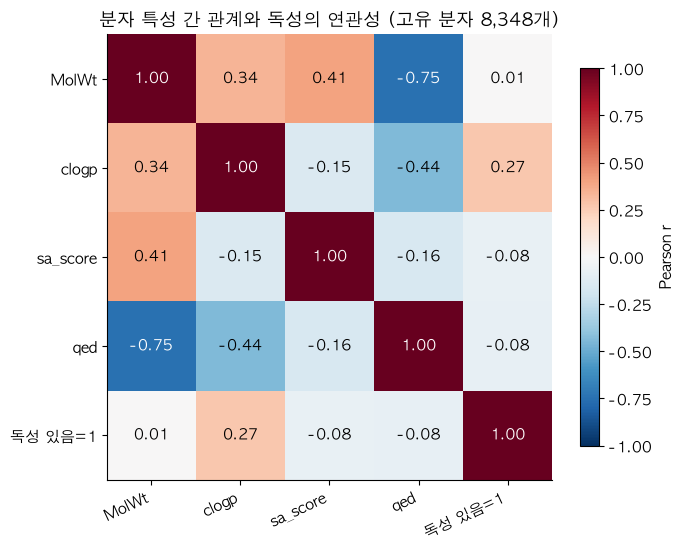

In [8]:
# 그래프 셀을 따로 실행해도 한글 글꼴 적용
from pathlib import Path as _FontPath
from matplotlib import font_manager as _font_manager
_font_path = _FontPath('/System/Library/Fonts/Supplemental/AppleGothic.ttf')
if _font_path.is_file():
    _font_manager.fontManager.addfont(str(_font_path))
    plt.rcParams['font.family'] = _font_manager.FontProperties(fname=str(_font_path)).get_name()
else:
    _korean_fonts = [f for f in ['NanumGothic', 'Nanum Gothic', 'Malgun Gothic', 'AppleGothic']
                     if f in _font_manager.get_font_names()]
    if not _korean_fonts:
        raise RuntimeError('한글 글꼴 설치 후 커널 재시작 필요: NanumGothic 또는 Malgun Gothic')
    plt.rcParams['font.family'] = _korean_fonts[0]
plt.rcParams['axes.unicode_minus'] = False

corr_columns = properties + ['toxic']
pearson = stat_df[corr_columns].corr(method='pearson')
spearman = stat_df[corr_columns].corr(method='spearman')
correlation_table = pd.DataFrame({
    '독성과 Pearson r': pearson.loc[properties, 'toxic'],
    '독성과 Spearman rho': spearman.loc[properties, 'toxic']})
display(correlation_table.round(4))
# Verify binary-continuous Pearson against point-biserial implementation.
for col in properties:
    r_pb = stats.pointbiserialr(stat_df.toxic, stat_df[col]).statistic
    np.testing.assert_allclose(r_pb, pearson.loc[col, 'toxic'], atol=1e-12)
fig, ax = plt.subplots(figsize=(7, 5.8))
mat = ax.imshow(pearson, cmap='RdBu_r', vmin=-1, vmax=1)
labels = properties + ['독성 있음=1']
ax.set_xticks(range(5), labels=labels, rotation=25, ha='right')
ax.set_yticks(range(5), labels=labels)
for i in range(5):
    for j in range(5):
        value = pearson.iloc[i,j]
        ax.text(j, i, f'{value:.2f}', ha='center', va='center',
                color='white' if abs(value)>0.6 else 'black')
fig.colorbar(mat, ax=ax, label='Pearson r', shrink=0.8)
ax.set_title('분자 특성 간 관계와 독성의 연관성 (고유 분자 8,348개)')
fig.tight_layout()
plt.show()

**쉽게 해석하면**

- `clogp`와 독성의 상관은 **r=0.273**, 순위 상관도 **0.280** → 지용성이 높은 쪽에서 독성이 더 자주 관찰되는 방향. 네 특성 중 상대적으로 가장 뚜렷하지만 단독 판정에는 부족
- 분자량과 독성은 **r=0.006** → 직선적인 관계가 거의 보이지 않는 수준
- `sa_score`와 `qed`는 각각 **r=-0.078, -0.084** → 독성과 약한 음의 관계
- 분자량과 `qed`의 r은 약 **-0.75** → 두 특성 사이에 겹치는 정보가 있을 가능성. 각각이 독립적인 독성 증거라는 해석은 주의

### 5-2. 평균 차이: 차이가 있는가, 얼마나 큰가?

독성 집단과 비독성 집단의 평균을 Welch 검정으로 비교. 결과는 아래 세 수치를 함께 확인.

| 수치 | 의미 | 읽을 때 주의할 점 |
| --- | --- | --- |
| 보정 p값 | 두 집단의 평균이 같다는 가정하에서 현재와 같은 차이를 설명하기 어려운 정도 | 0.05 미만이면 평균 차이의 통계적 근거. 작다고 차이가 크거나 유용하다는 뜻은 아님 |
| 효과크기, Hedges g | 단위가 다른 특성끼리 차이의 크기를 비교할 수 있도록 맞춘 값 | 0 근처면 차이가 작음. 양수는 독성 집단이 높고 음수는 낮은 방향 |
| 95% 신뢰구간 | 평균 차이 추정의 불확실성을 나타내는 범위 | 0을 포함하면 차이가 없을 가능성도 남아 있음. 아래 구간은 특성별 구간 |

- **보정**: 여러 특성을 비교하다 우연히 차이가 있다고 판단하는 문제를 줄이는 처리. 분자 특성 4개에는 Holm 보정 적용
- **부트스트랩**: 같은 데이터를 다시 뽑아 2,000번 계산한 확인 방법. 다른 데이터로 재검증한 것은 아님

아래 그래프의 점은 평균 차이, 선은 그 차이의 95% 구간. 두 계산 방법에서 비슷한 범위가 나오는지 확인.

,독성 평균,비독성 평균,평균 차이,Hedges g,p,Holm 보정 p,평균 차이 근거
특성,,,,,,,
MolWt,443.8031,442.7641,1.0389,0.0117,5.905e-01,5.905e-01,False
clogp,4.2061,3.4500,0.7560,0.5698,3.490e-144,1.396e-143,True
sa_score,3.1257,3.2393,-0.1136,-0.1566,7.244e-13,1.449e-12,True
qed,0.5422,0.5734,-0.0313,-0.1690,2.540e-14,7.619e-14,True


,표준오차,t,자유도,Welch 하한,Welch 상한,Bootstrap 하한,Bootstrap 상한
특성,,,,,,,
MolWt,1.93047,0.53818,8330.68621,-2.74526,4.82314,-2.86833,4.67965
clogp,0.02898,26.08361,8247.61125,0.69920,0.81283,0.70208,0.81535
sa_score,0.01581,-7.18611,8289.96831,-0.14463,-0.08264,-0.14601,-0.08384
qed,0.00409,-7.63424,7826.85232,-0.03929,-0.02323,-0.03928,-0.02304


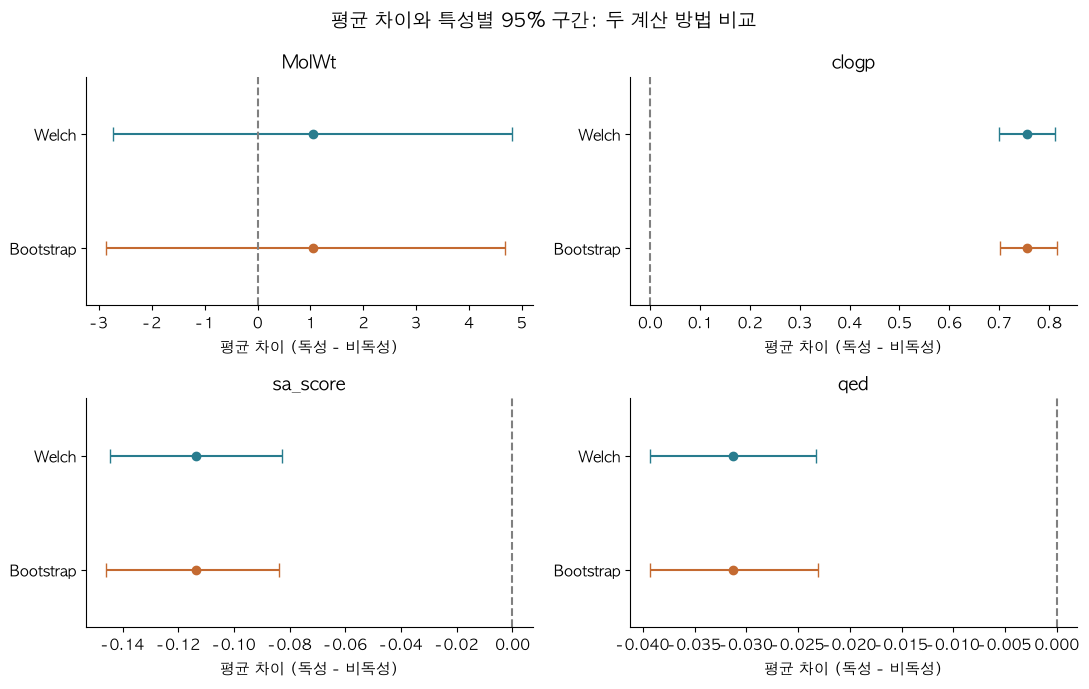

In [9]:
# 그래프 셀을 따로 실행해도 한글 글꼴 적용
from pathlib import Path as _FontPath
from matplotlib import font_manager as _font_manager
_font_path = _FontPath('/System/Library/Fonts/Supplemental/AppleGothic.ttf')
if _font_path.is_file():
    _font_manager.fontManager.addfont(str(_font_path))
    plt.rcParams['font.family'] = _font_manager.FontProperties(fname=str(_font_path)).get_name()
else:
    _korean_fonts = [f for f in ['NanumGothic', 'Nanum Gothic', 'Malgun Gothic', 'AppleGothic']
                     if f in _font_manager.get_font_names()]
    if not _korean_fonts:
        raise RuntimeError('한글 글꼴 설치 후 커널 재시작 필요: NanumGothic 또는 Malgun Gothic')
    plt.rcParams['font.family'] = _korean_fonts[0]
plt.rcParams['axes.unicode_minus'] = False

rng = np.random.default_rng(225)
property_rows = []
for col in properties:
    a = stat_df.loc[stat_df.toxic.eq(1), col].to_numpy()
    b = stat_df.loc[stat_df.toxic.eq(0), col].to_numpy()
    na, nb_ = len(a), len(b)
    va, vb = a.var(ddof=1), b.var(ddof=1)
    delta = a.mean() - b.mean()
    se = np.sqrt(va/na + vb/nb_)
    dof = (va/na+vb/nb_)**2 / ((va/na)**2/(na-1)+(vb/nb_)**2/(nb_-1))
    t_manual = delta/se
    p_manual = 2*stats.t.sf(abs(t_manual), dof)
    test = stats.ttest_ind(a, b, equal_var=False, alternative='two-sided')
    np.testing.assert_allclose([t_manual,p_manual], [test.statistic,test.pvalue], rtol=1e-10)
    lo, hi = delta + np.array([-1,1])*stats.t.ppf(.975,dof)*se
    pooled_sd = np.sqrt(((na-1)*va+(nb_-1)*vb)/(na+nb_-2))
    g = (1 - 3/(4*(na+nb_)-9))*delta/pooled_sd
    boot = []
    for start in range(0, 2000, 100):
        da = rng.choice(a, size=(100,na), replace=True).mean(axis=1)
        db = rng.choice(b, size=(100,nb_), replace=True).mean(axis=1)
        boot.extend(da-db)
    boot_lo, boot_hi = np.quantile(boot,[.025,.975])
    property_rows.append({'특성':col, '독성 평균':a.mean(), '비독성 평균':b.mean(),
                          '평균 차이':delta, '표준오차':se, 't':t_manual, '자유도':dof,
                          'p':p_manual, 'Hedges g':g,
                          'Welch 하한':lo, 'Welch 상한':hi,
                          'Bootstrap 하한':boot_lo, 'Bootstrap 상한':boot_hi})
property_tests = pd.DataFrame(property_rows).set_index('특성')
property_tests['Holm 보정 p'] = holm_adjust(property_tests.p)
property_tests['평균 차이 근거'] = property_tests['Holm 보정 p'] < .05
# Detailed calculation table remains inspectable without rounding p-values to zero.
display(property_tests[['독성 평균','비독성 평균','평균 차이','Hedges g','p',
                        'Holm 보정 p','평균 차이 근거']].style.format({
    **{c:'{:.4f}' for c in ['독성 평균','비독성 평균','평균 차이','Hedges g']},
    'p':'{:.3e}', 'Holm 보정 p':'{:.3e}'}))
display(property_tests[['표준오차','t','자유도','Welch 하한','Welch 상한',
                        'Bootstrap 하한','Bootstrap 상한']].round(5))
# Compare the same mean difference with two pointwise interval procedures.
fig,axes=plt.subplots(2,2,figsize=(11,7))
for ax,(col,row) in zip(axes.flat,property_tests.iterrows()):
    center=row['평균 차이']
    for y,method,color in [(1,'Welch','#287C8E'),(0,'Bootstrap','#C46A31')]:
        lo,hi=row[method+' 하한'],row[method+' 상한']
        ax.errorbar(center,y,xerr=[[center-lo],[hi-center]],fmt='o',color=color,capsize=5)
    ax.axvline(0,color='gray',linestyle='--')
    ax.set_yticks([0,1],labels=['Bootstrap','Welch'])
    ax.set(title=col,xlabel='평균 차이 (독성 - 비독성)',ylim=(-.5,1.5))
fig.suptitle('평균 차이와 특성별 95% 구간: 두 계산 방법 비교',fontsize=14)
fig.tight_layout();plt.show()

**쉽게 해석하면**

| 특성 | Holm 보정 p | Hedges g | 결론 |
| --- | --- | --- | --- |
| `MolWt` | 0.590 | 0.012 | 평균 차이의 근거 부족. 두 집단이 완전히 같다는 입증은 아님 |
| `clogp` | 약 1.40×10⁻¹⁴³ | 0.570 | 독성 집단에서 평균이 높고, 네 특성 중 표준화 차이도 가장 큼 |
| `sa_score` | 약 1.45×10⁻¹² | -0.157 | 독성 집단에서 평균이 낮지만 차이 크기는 작음 |
| `qed` | 약 7.62×10⁻¹⁴ | -0.169 | 독성 집단에서 평균이 낮지만 차이 크기는 작음 |

`clogp`의 **평균 차이=0.756**, Welch 95% 구간 **[0.699, 0.813]**, 부트스트랩 구간 **[0.702, 0.815]**. 서로 다른 계산에서도 차이의 방향과 범위가 비슷한 결과.

**숫자로 읽으면**: 독성 집단의 clogp 평균이 약 0.76 높게 나타남. 두 방법의 구간이 모두 0보다 위에 있어, 독성 집단이 높은 방향을 일관되게 뒷받침. sa_score와 qed는 p값이 작아도 효과크기가 작으므로 실제 차이는 크지 않다는 해석.

신뢰구간은 추정의 불확실성을 보여주는 값이며, 특정 물질의 독성 확률이나 분류 정확도를 의미하지 않음.

### 5-3. Fingerprint: 특정 구조 신호가 있을 때 독성이 더 많은가?

**분할표**: 비트가 켜진 물질과 꺼진 물질에서 실제 독성 유무를 센 표. 예측 성능을 나타내는 혼동행렬과 구분.

Fisher 검정으로 비트와 독성의 연관성을 확인하고, 수천 개 비트를 비교하는 데 따른 우연한 발견을 줄이기 위해 BY 보정 적용.

| 수치 | 의미 |
| --- | --- |
| 활성 표본 수 | 해당 비트가 1인 분자 수. 소수 표본의 높은 비율은 신중한 해석 필요 |
| 활성 독성률 | 비트가 1인 분자 중 독성 물질의 비율 |
| 비활성 독성률 | 비트가 0인 분자 중 독성 물질의 비율 |
| 독성률 차이(%p) | 두 집단의 독성 비율 차이. 예: 60%와 40%의 차이는 20%p |
| phi | 비트와 독성의 상관. 양수는 활성 집단에서 독성이 더 많은 방향 |
| BY 보정 p값 | 많은 비트를 동시에 살펴본 점을 반영한 연관성 판단 기준. 0.05 미만을 탐색 후보로 선정 |

BY 보정도 각 후보가 진짜일 확률을 알려주는 것은 아님. 상위 비트는 원인 규명보다 **추가 확인할 구조 신호 후보**로 해석.

검정 비트: 3,023개 / 상수로 제외: 49개
원래 p<0.05: 1,451개 → BY 보정 후: 852개


,검정수,발견수
묶음,,
ecfp,1024,274
fcfp,1024,253
ptfp,975,325


,활성 표본 수,비활성 표본 수,활성 독성률(%),비활성 독성률(%),독성률 차이(%p),phi,p,BY 보정 p
비트,,,,,,,,
fcfp_146,348,8000,88.79,43.73,45.07,0.181,6.587e-67,1.711e-62
ecfp_807,5278,3070,38.44,57.92,-19.47,-0.189,1.703e-66,2.212e-62
ecfp_650,6301,2047,40.53,61.21,-20.68,-0.179,1.004e-59,8.694e-56
fcfp_18,4040,4308,54.55,37.21,17.34,0.174,4.938e-57,3.206e-53
ecfp_425,455,7893,80.66,43.58,37.08,0.169,4.387e-56,2.279e-52
ecfp_893,4631,3717,38.05,55.02,-16.97,-0.169,4.060e-54,1.757e-50
fcfp_445,275,8073,89.09,44.12,44.97,0.161,1.710e-53,6.346e-50
ptfp_376,583,7765,75.47,43.36,32.11,0.164,3.989e-52,1.295e-48
fcfp_526,422,7926,80.57,43.74,36.83,0.162,1.530e-51,4.417e-48


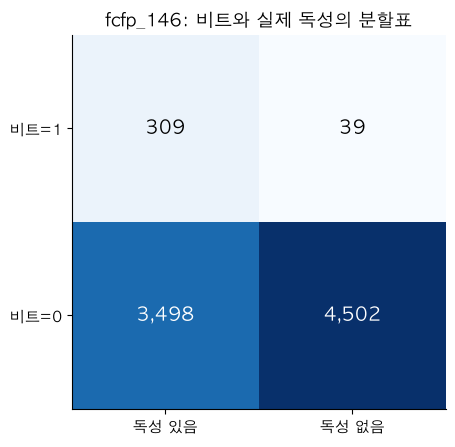

In [10]:
# 그래프 셀을 따로 실행해도 한글 글꼴 적용
from pathlib import Path as _FontPath
from matplotlib import font_manager as _font_manager
_font_path = _FontPath('/System/Library/Fonts/Supplemental/AppleGothic.ttf')
if _font_path.is_file():
    _font_manager.fontManager.addfont(str(_font_path))
    plt.rcParams['font.family'] = _font_manager.FontProperties(fname=str(_font_path)).get_name()
else:
    _korean_fonts = [f for f in ['NanumGothic', 'Nanum Gothic', 'Malgun Gothic', 'AppleGothic']
                     if f in _font_manager.get_font_names()]
    if not _korean_fonts:
        raise RuntimeError('한글 글꼴 설치 후 커널 재시작 필요: NanumGothic 또는 Malgun Gothic')
    plt.rcParams['font.family'] = _korean_fonts[0]
plt.rcParams['axes.unicode_minus'] = False

toxic_mask=stat_df.toxic.eq(1).to_numpy()
bit_values=stat_df[fp_columns].to_numpy(dtype=np.int64)
a_all=bit_values[toxic_mask].sum(axis=0)
b_all=bit_values[~toxic_mask].sum(axis=0)
nt,nn=int(toxic_mask.sum()),int((~toxic_mask).sum())
bit_rows=[]
for i,col in enumerate(fp_columns):
    a,b=int(a_all[i]),int(b_all[i]); c,d=nt-a,nn-b
    if a+b==0 or c+d==0: continue
    test=stats.fisher_exact([[a,b],[c,d]],alternative='two-sided')
    phi=(a*d-b*c)/np.sqrt(float((a+b)*(c+d)*(a+c)*(b+d)))
    bit_rows.append({'비트':col,'a':a,'b':b,'c':c,'d':d,
                     '활성 표본 수':a+b,'비활성 표본 수':c+d,
                     '활성 독성률(%)':100*a/(a+b),'비활성 독성률(%)':100*c/(c+d),
                     '독성률 차이(%p)':100*(a/(a+b)-c/(c+d)),
                     'phi':phi,'p':test.pvalue})
bit_tests=pd.DataFrame(bit_rows).rename(columns={'비트':'비트'}).set_index('비트')
bit_tests['BY 보정 p']=stats.false_discovery_control(bit_tests.p.to_numpy(),method='by')
bit_tests['보정 후 근거']=bit_tests['BY 보정 p']<.05
print(f'검정 비트: {len(bit_tests):,}개 / 상수로 제외: {len(fp_columns)-len(bit_tests)}개')
print(f'원래 p<0.05: {int((bit_tests.p<.05).sum()):,}개 → BY 보정 후: {int(bit_tests["보정 후 근거"].sum()):,}개')
bit_tests['묶음']=bit_tests.index.str.split('_').str[0]
display(bit_tests.groupby('묶음').agg(검정수=('p','size'),발견수=('보정 후 근거','sum')))
top_bits=bit_tests.sort_values('BY 보정 p').head(10)
display(top_bits[['활성 표본 수','비활성 표본 수','활성 독성률(%)','비활성 독성률(%)',
                  '독성률 차이(%p)','phi','p','BY 보정 p']].style.format({
    '활성 독성률(%)':'{:.2f}','비활성 독성률(%)':'{:.2f}','독성률 차이(%p)':'{:.2f}',
    'phi':'{:.3f}','p':'{:.3e}','BY 보정 p':'{:.3e}'}))
# A top-ranked table illustrates the actual calculation, not out-of-sample confirmation.
example_bit=top_bits.index[0]
r=bit_tests.loc[example_bit]
contingency=np.array([[int(r.a),int(r.b)],[int(r.c),int(r.d)]])
assert contingency.sum()==len(stat_df)
assert contingency[:,0].sum()==nt
np.testing.assert_allclose(stats.fisher_exact(contingency).pvalue,r.p)
fig,ax=plt.subplots(figsize=(6,4.6))
ax.imshow(contingency,cmap='Blues')
for i in range(2):
    for j in range(2):
        ax.text(j,i,f'{contingency[i,j]:,}',ha='center',va='center',
                color='white' if contingency[i,j]>contingency.max()*.55 else 'black',fontsize=14)
ax.set_xticks([0,1],labels=['독성 있음','독성 없음'])
ax.set_yticks([0,1],labels=['비트=1','비트=0'])
ax.set_title(f'{example_bit}: 비트와 실제 독성의 분할표')
fig.tight_layout(); plt.show()

**쉽게 해석하면**

- 3,072개 비트 중 상수 49개를 제외한 **3,023개 검정**
- 보정 전 p<0.05는 1,451개, 의존성을 허용하는 BY 보정 후 기준을 통과한 비트는 **852개**
- 852개가 서로 독립된 구조나 독성 원인 852개라는 뜻은 아님. 비트끼리 중복된 신호를 포함할 가능성 존재

예시 `fcfp_146`은 활성 분자 348개 중 309개가 독성 → **88.79%**. 비활성 분자는 8,000개 중 3,498개가 독성 → **43.73%**. 차이는 **45.07%p**, phi는 **0.181**.

특정 집단의 높은 독성 비율과 전체 분자에 대한 구분 능력은 다른 개념. 이 비트의 독성 예측 정확도가 88.79%라는 뜻으로 해석 불가. 전체 자료에서 선택한 상위 결과이므로 독립 자료에서 재확인 필요.

### 계산 확인

검정값과 보정값을 별도 계산으로 대조하여 일치 확인. 상세 검산 코드는 접은 상태로 보관.

In [11]:
# Recompute a two-sided Fisher p-value by summing hypergeometric table probabilities.
N=int(contingency.sum()); K=int(contingency[:,0].sum()); draws=int(contingency[0].sum())
observed=int(contingency[0,0])
possible=np.arange(max(0,draws-(N-K)),min(draws,K)+1)
log_probs=stats.hypergeom.logpmf(possible,N,K,draws)
log_observed=stats.hypergeom.logpmf(observed,N,K,draws)
fisher_manual=float(np.exp(log_probs[log_probs<=log_observed+1e-12]).sum())
fisher_library=float(stats.fisher_exact(contingency).pvalue)
np.testing.assert_allclose(fisher_manual,fisher_library,rtol=1e-8,atol=0)
# Recompute BY adjusted p-values from its sorted formula.
raw=bit_tests.p.to_numpy(); order=np.argsort(raw); m=len(raw)
harmonic=np.sum(1/np.arange(1,m+1))
ordered_adj=np.minimum(1,np.minimum.accumulate((m*harmonic*raw[order]/np.arange(1,m+1))[::-1])[::-1])
manual_by=np.empty(m);manual_by[order]=ordered_adj
np.testing.assert_allclose(manual_by,bit_tests['BY 보정 p'],rtol=1e-12,atol=0)
assert np.isfinite(property_tests.select_dtypes(include='number').to_numpy()).all()
assert ((bit_tests['BY 보정 p']>=0)&(bit_tests['BY 보정 p']<=1)).all()
print(f'Fisher 직접 확률 합산: {fisher_manual:.6e} / SciPy: {fisher_library:.6e}')
print('검산 완료: Welch 수식 4개, 점이연 상관 4개, Fisher 분할표 예시, BY 보정 전체')

Fisher 직접 확률 합산: 6.586840e-67 / SciPy: 6.586840e-67
검산 완료: Welch 수식 4개, 점이연 상관 4개, Fisher 분할표 예시, BY 보정 전체


### 5-4. 이번 분석에서 가져갈 결론

1. **우선 살펴볼 특성은 clogp**: 네 분자 특성 중 독성과의 연관성과 집단 차이가 가장 뚜렷
2. **sa_score와 qed는 보조 정보 후보**: 통계적 차이는 있지만 크기는 작아 과도한 의미 부여 주의
3. **분자량 단독으로는 차이 근거 부족**: 다른 특성과의 조합에서도 쓸모없다는 결론은 아님
4. **Fingerprint에 추가 단서 존재**: 후보 비트의 구조 의미와 다른 데이터에서의 재현 여부 확인 필요

현재 결과는 분자들이 서로 독립이라는 가정하의 탐색 결과. 비슷한 골격끼리의 관계와 실험 조건은 보정하지 않았으며, 독성 원인이나 사람에 대한 안전성을 입증한 것은 아님.

방법 참고: [Welch 검정](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.ttest_ind.html), [Fisher 검정](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.fisher_exact.html), [다중검정 보정](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.false_discovery_control.html)

## 6. 분자별 산점도: 독성 물질은 어디에 모이는가?

**점 하나 = 분자 하나, 색 = 실제 독성 여부.** 구조 중복을 제외한 8,348개 분자 전체 사용. 예측 결과가 아닌 실제 정답을 덧칠한 그림.

### 6-1. 분자 특성 두 개씩 비교

가로축과 세로축에 실제 분자 특성을 배치하여, 어떤 조합에서 독성 물질이 많이 나타나는지 확인.

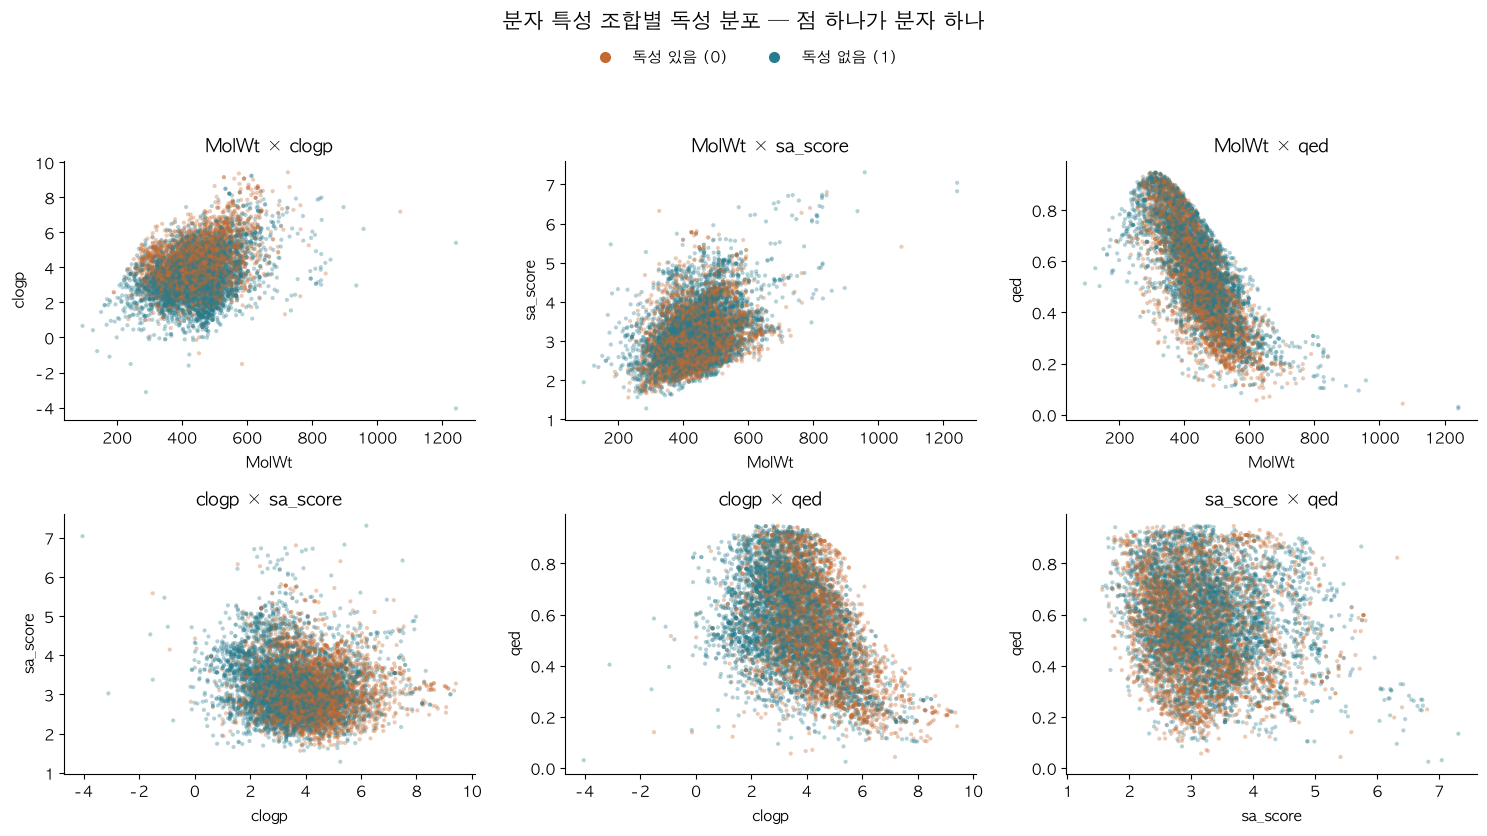

In [12]:
# 그래프 셀을 따로 실행해도 한글 글꼴 적용
from pathlib import Path as _FontPath
from matplotlib import font_manager as _font_manager
_font_path = _FontPath('/System/Library/Fonts/Supplemental/AppleGothic.ttf')
if _font_path.is_file():
    _font_manager.fontManager.addfont(str(_font_path))
    plt.rcParams['font.family'] = _font_manager.FontProperties(fname=str(_font_path)).get_name()
else:
    _korean_fonts = [f for f in ['NanumGothic', 'Nanum Gothic', 'Malgun Gothic', 'AppleGothic']
                     if f in _font_manager.get_font_names()]
    if not _korean_fonts:
        raise RuntimeError('한글 글꼴 설치 후 커널 재시작 필요: NanumGothic 또는 Malgun Gothic')
    plt.rcParams['font.family'] = _korean_fonts[0]
plt.rcParams['axes.unicode_minus'] = False

from itertools import combinations
from matplotlib.lines import Line2D

scatter_df = stat_df.copy()
feature_pairs = list(combinations(properties, 2))
# Randomize drawing order so the last class drawn does not cover the other class.
draw_order = np.random.default_rng(225).permutation(len(scatter_df))
plot_df = scatter_df.iloc[draw_order]
point_colors = plot_df['label'].map(COLORS).to_numpy()
legend_handles = [Line2D([0], [0], marker='o', linestyle='', color=COLORS[k],
                         label=NAMES[k], markersize=7) for k in [0, 1]]
fig, axes = plt.subplots(2, 3, figsize=(15, 8.5))
for ax, (x_col, y_col) in zip(axes.flat, feature_pairs):
    ax.scatter(plot_df[x_col], plot_df[y_col], c=point_colors,
               s=9, alpha=.35, linewidths=0, rasterized=True)
    ax.set(xlabel=x_col, ylabel=y_col, title=f'{x_col} × {y_col}')
fig.legend(handles=legend_handles, loc='upper center', ncol=2,
           bbox_to_anchor=(.5, .95), frameon=False)
fig.suptitle('분자 특성 조합별 독성 분포 — 점 하나가 분자 하나', fontsize=15)
fig.tight_layout(rect=[0, 0, 1, .90])
plt.show()

**왜 그렸는가?** 하나의 특성만으로 안 보이던 독성 분포가 두 특성을 함께 볼 때 나타나는지 확인.

| 축 조합 | 확인할 질문 |
| --- | --- |
| 분자량 × 지용성 | 비슷한 분자량에서도 지용성에 따라 색 분포가 달라지는가? |
| 분자량 × 합성 난이도 | 분자 크기와 합성 난이도가 함께 높을 때 독성이 몰리는가? |
| 분자량 × 약물 유사도 | 크기와 약물 유사도의 관계 속에서 독성 색이 따로 모이는가? |
| 지용성 × 합성 난이도 | 지용성이 높을 때 합성 난이도에 따라 독성 분포가 달라지는가? |
| 지용성 × 약물 유사도 | 독성과 가장 연관된 지용성에 약물 유사도를 함께 보면 구분되는가? |
| 합성 난이도 × 약물 유사도 | 약한 개별 특성도 조합하면 구분의 단서가 생기는가? |

**어떻게 그렸는가?** 4개 특성의 가능한 조합 6개를 실제 값 그대로 표시. 점을 반투명하게 하고 그리는 순서를 섞어 한 색이 다른 색을 가리는 현상 완화. 극단값은 제거하지 않음.

점이 많이 겹친 구역은 색만으로 정확한 독성 비율을 읽기 어려우므로, 경계나 비율의 확정 판단과 구분.

**관찰한 점**: 지용성이 높은 쪽에서 독성 색이 더 눈에 띄지만 대부분의 조합에서 두 색이 많이 겹침. 분자량과 약물 유사도 사이에는 뚜렷한 관계가 보이지만, 그 관계 자체가 독성 유무를 나누는 경계는 아님.

### 6-2. Fingerprint 분자 지도

**UMAP**: 수천 개 구조 정보를 두 좌표로 줄여, 구조 표현이 비슷한 분자를 가까이 배치하려는 방법. 지도 좌표는 분자량이나 독성 점수가 아님.

**Jaccard 거리**: 두 분자의 켜진 비트가 얼마나 겹치는지를 비교하는 방식. 가까운 점들이 독성 색도 비슷한지 관찰.

ECFP, FCFP, PTFP를 각각 별도 지도로 작성. **독성 label은 좌표 계산에서 제외하고 완성된 지도에 색으로만 표시.**

추가 패키지: `umap-learn`. 현재 커널에 없다면 `%pip install umap-learn` 실행 후 커널 재시작 필요.

#### ECFP 지도

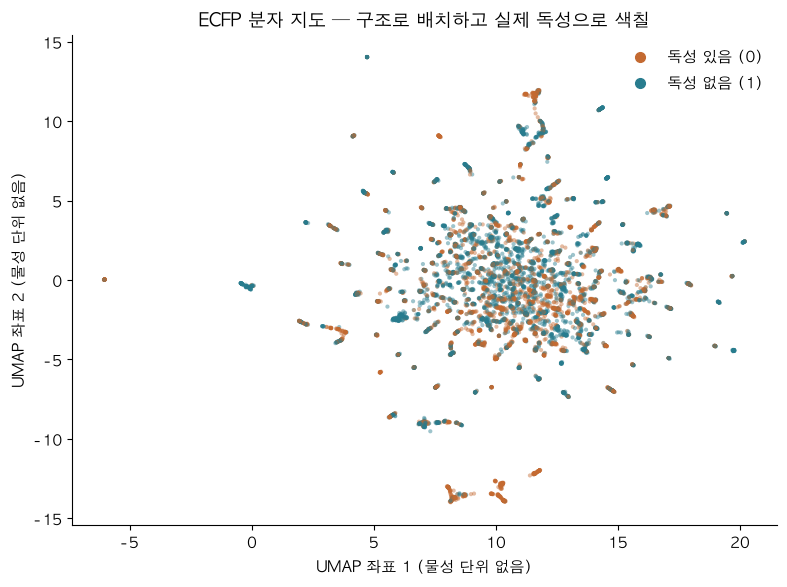

분자 8,348개 / 사용 비트 1,024개 / 제외한 상수 0개


In [13]:
# 그래프 셀을 따로 실행해도 한글 글꼴 적용
from pathlib import Path as _FontPath
from matplotlib import font_manager as _font_manager
_font_path = _FontPath('/System/Library/Fonts/Supplemental/AppleGothic.ttf')
if _font_path.is_file():
    _font_manager.fontManager.addfont(str(_font_path))
    plt.rcParams['font.family'] = _font_manager.FontProperties(fname=str(_font_path)).get_name()
else:
    _korean_fonts = [f for f in ['NanumGothic', 'Nanum Gothic', 'Malgun Gothic', 'AppleGothic']
                     if f in _font_manager.get_font_names()]
    if not _korean_fonts:
        raise RuntimeError('한글 글꼴 설치 후 커널 재시작 필요: NanumGothic 또는 Malgun Gothic')
    plt.rcParams['font.family'] = _korean_fonts[0]
plt.rcParams['axes.unicode_minus'] = False

import umap

umap_maps = {}
umap_inputs = {}
umap_metadata = []
group = 'ecfp'
columns = fp_groups[group]
# Constant bits provide no discrimination; exclude within this descriptive full-data map.
variable_columns = [c for c in columns if scatter_df[c].nunique() > 1]
X_map = scatter_df[variable_columns].to_numpy(dtype=bool)
assert X_map.shape[0] == len(scatter_df)
assert X_map.any(axis=1).all(), '활성 비트가 없는 분자 확인 필요'
mapper = umap.UMAP(n_components=2, metric='jaccard', n_neighbors=30,
                   min_dist=0.15, random_state=225, n_jobs=1, low_memory=True)
# Do not pass label or toxic as y: map positions use structural features only.
coords = mapper.fit_transform(X_map)
assert np.isfinite(coords).all()
umap_maps[group] = coords
umap_inputs[group] = X_map
umap_metadata.append({'표현':group.upper(), '입력 비트':len(variable_columns),
                      '제외한 상수 비트':len(columns)-len(variable_columns)})
fig, ax = plt.subplots(figsize=(8, 6))
ax.scatter(coords[draw_order, 0], coords[draw_order, 1], c=point_colors,
           s=9, alpha=.45, linewidths=0, rasterized=True)
ax.legend(handles=legend_handles, frameon=False, loc='best')
ax.set(title=f'{group.upper()} 분자 지도 — 구조로 배치하고 실제 독성으로 색칠',
       xlabel='UMAP 좌표 1 (물성 단위 없음)', ylabel='UMAP 좌표 2 (물성 단위 없음)')
fig.tight_layout(); plt.show()
print(f'분자 {len(scatter_df):,}개 / 사용 비트 {len(variable_columns):,}개 / 제외한 상수 {len(columns)-len(variable_columns)}개')

**왜 그렸는가?** 원자 주변의 연결 구조가 비슷한 분자끼리 독성 여부도 비슷한지 확인.

**어떻게 그렸는가?** ECFP 1,024개 비트의 유사도로 두 좌표 계산 후 독성 색을 덧칠. 독성 정답과 분자 특성 4개는 좌표 계산에 미사용.

**관찰한 점**: 중심부는 두 색이 많이 섞이고, 일부 주변의 작은 묶음에서 독성 색이 집중된 모습. 그 묶음의 실제 분자와 비율을 추가 확인할 후보.

#### FCFP 지도

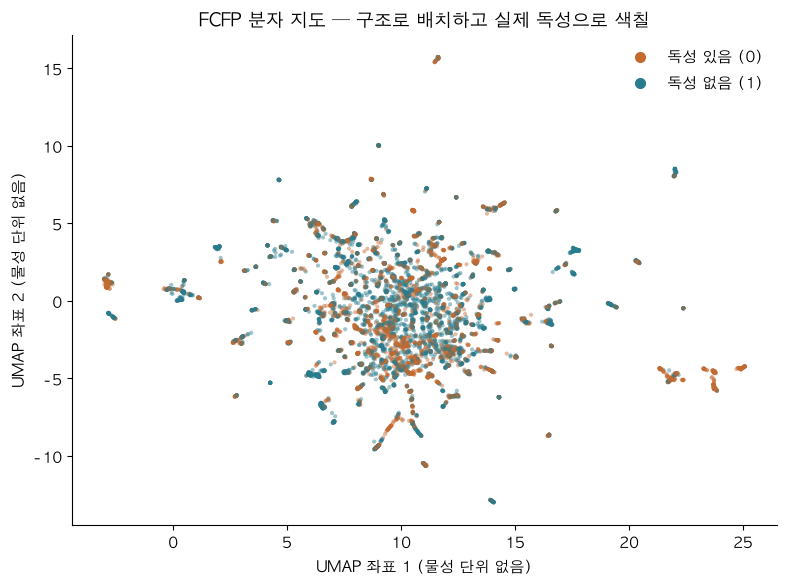

분자 8,348개 / 사용 비트 1,024개 / 제외한 상수 0개


In [14]:
# 그래프 셀을 따로 실행해도 한글 글꼴 적용
from pathlib import Path as _FontPath
from matplotlib import font_manager as _font_manager
_font_path = _FontPath('/System/Library/Fonts/Supplemental/AppleGothic.ttf')
if _font_path.is_file():
    _font_manager.fontManager.addfont(str(_font_path))
    plt.rcParams['font.family'] = _font_manager.FontProperties(fname=str(_font_path)).get_name()
else:
    _korean_fonts = [f for f in ['NanumGothic', 'Nanum Gothic', 'Malgun Gothic', 'AppleGothic']
                     if f in _font_manager.get_font_names()]
    if not _korean_fonts:
        raise RuntimeError('한글 글꼴 설치 후 커널 재시작 필요: NanumGothic 또는 Malgun Gothic')
    plt.rcParams['font.family'] = _korean_fonts[0]
plt.rcParams['axes.unicode_minus'] = False

group = 'fcfp'
columns = fp_groups[group]
# Constant bits provide no discrimination; exclude within this descriptive full-data map.
variable_columns = [c for c in columns if scatter_df[c].nunique() > 1]
X_map = scatter_df[variable_columns].to_numpy(dtype=bool)
assert X_map.shape[0] == len(scatter_df)
assert X_map.any(axis=1).all(), '활성 비트가 없는 분자 확인 필요'
mapper = umap.UMAP(n_components=2, metric='jaccard', n_neighbors=30,
                   min_dist=0.15, random_state=225, n_jobs=1, low_memory=True)
# Do not pass label or toxic as y: map positions use structural features only.
coords = mapper.fit_transform(X_map)
assert np.isfinite(coords).all()
umap_maps[group] = coords
umap_inputs[group] = X_map
umap_metadata.append({'표현':group.upper(), '입력 비트':len(variable_columns),
                      '제외한 상수 비트':len(columns)-len(variable_columns)})
fig, ax = plt.subplots(figsize=(8, 6))
ax.scatter(coords[draw_order, 0], coords[draw_order, 1], c=point_colors,
           s=9, alpha=.45, linewidths=0, rasterized=True)
ax.legend(handles=legend_handles, frameon=False, loc='best')
ax.set(title=f'{group.upper()} 분자 지도 — 구조로 배치하고 실제 독성으로 색칠',
       xlabel='UMAP 좌표 1 (물성 단위 없음)', ylabel='UMAP 좌표 2 (물성 단위 없음)')
fig.tight_layout(); plt.show()
print(f'분자 {len(scatter_df):,}개 / 사용 비트 {len(variable_columns):,}개 / 제외한 상수 {len(columns)-len(variable_columns)}개')

**왜 그렸는가?** 원자의 화학적 기능이 비슷한 분자끼리 독성 여부도 비슷한지 확인.

**어떻게 그렸는가?** FCFP 1,024개 비트만으로 좌표 계산 후 독성 색을 표시. ECFP와 같은 UMAP 설정 사용.

**관찰한 점**: 중심부는 두 색이 섞이며 일부 작은 묶음에서 색이 치우친 모습. ECFP 지도와 같은 위치나 모양을 기대할 수 없으며, 분리된 묶음을 독성 원인으로 단정 불가.

#### PTFP 지도

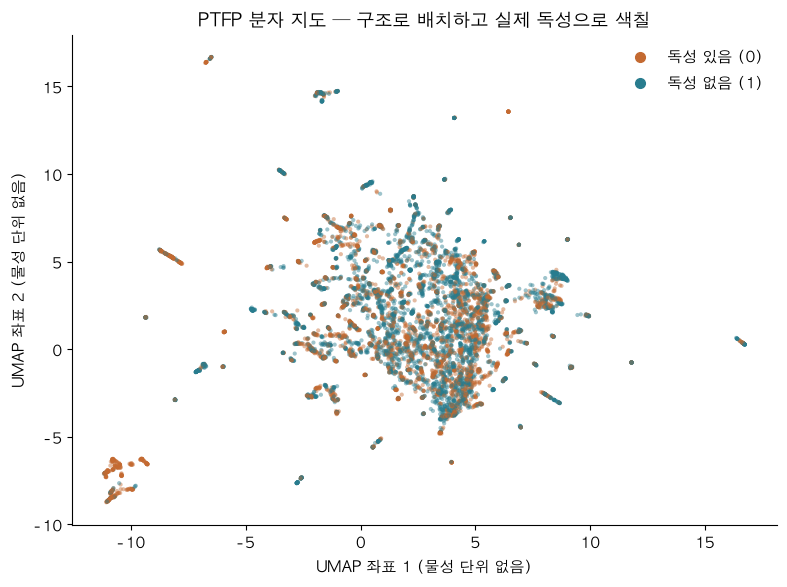

분자 8,348개 / 사용 비트 975개 / 제외한 상수 49개


In [15]:
# 그래프 셀을 따로 실행해도 한글 글꼴 적용
from pathlib import Path as _FontPath
from matplotlib import font_manager as _font_manager
_font_path = _FontPath('/System/Library/Fonts/Supplemental/AppleGothic.ttf')
if _font_path.is_file():
    _font_manager.fontManager.addfont(str(_font_path))
    plt.rcParams['font.family'] = _font_manager.FontProperties(fname=str(_font_path)).get_name()
else:
    _korean_fonts = [f for f in ['NanumGothic', 'Nanum Gothic', 'Malgun Gothic', 'AppleGothic']
                     if f in _font_manager.get_font_names()]
    if not _korean_fonts:
        raise RuntimeError('한글 글꼴 설치 후 커널 재시작 필요: NanumGothic 또는 Malgun Gothic')
    plt.rcParams['font.family'] = _korean_fonts[0]
plt.rcParams['axes.unicode_minus'] = False

group = 'ptfp'
columns = fp_groups[group]
# Constant bits provide no discrimination; exclude within this descriptive full-data map.
variable_columns = [c for c in columns if scatter_df[c].nunique() > 1]
X_map = scatter_df[variable_columns].to_numpy(dtype=bool)
assert X_map.shape[0] == len(scatter_df)
assert X_map.any(axis=1).all(), '활성 비트가 없는 분자 확인 필요'
mapper = umap.UMAP(n_components=2, metric='jaccard', n_neighbors=30,
                   min_dist=0.15, random_state=225, n_jobs=1, low_memory=True)
# Do not pass label or toxic as y: map positions use structural features only.
coords = mapper.fit_transform(X_map)
assert np.isfinite(coords).all()
umap_maps[group] = coords
umap_inputs[group] = X_map
umap_metadata.append({'표현':group.upper(), '입력 비트':len(variable_columns),
                      '제외한 상수 비트':len(columns)-len(variable_columns)})
fig, ax = plt.subplots(figsize=(8, 6))
ax.scatter(coords[draw_order, 0], coords[draw_order, 1], c=point_colors,
           s=9, alpha=.45, linewidths=0, rasterized=True)
ax.legend(handles=legend_handles, frameon=False, loc='best')
ax.set(title=f'{group.upper()} 분자 지도 — 구조로 배치하고 실제 독성으로 색칠',
       xlabel='UMAP 좌표 1 (물성 단위 없음)', ylabel='UMAP 좌표 2 (물성 단위 없음)')
fig.tight_layout(); plt.show()
print(f'분자 {len(scatter_df):,}개 / 사용 비트 {len(variable_columns):,}개 / 제외한 상수 {len(columns)-len(variable_columns)}개')

**왜 그렸는가?** 분자 구조 패턴으로 묶었을 때도 독성 색이 모이는 영역이 있는지 확인.

**어떻게 그렸는가?** 모든 값이 1인 49개 비트를 제외하고 PTFP 975개 비트로 좌표 계산. 독성 정답은 색칠에만 사용.

**관찰한 점**: 넓은 영역에서 두 색이 겹치고 일부 작은 묶음에서 색이 치우친 모습. 구조 패턴만으로 독성 유무가 두 영역으로 명확하게 나뉘지는 않음.

### 6-3. 지도 설정에 따른 변화 확인

같은 ECFP로 난수 고정값만 바꿔 한 번 더 표시. 한 번 그린 지도의 덩어리나 방향을 고정된 구조로 오해하지 않도록 확인.

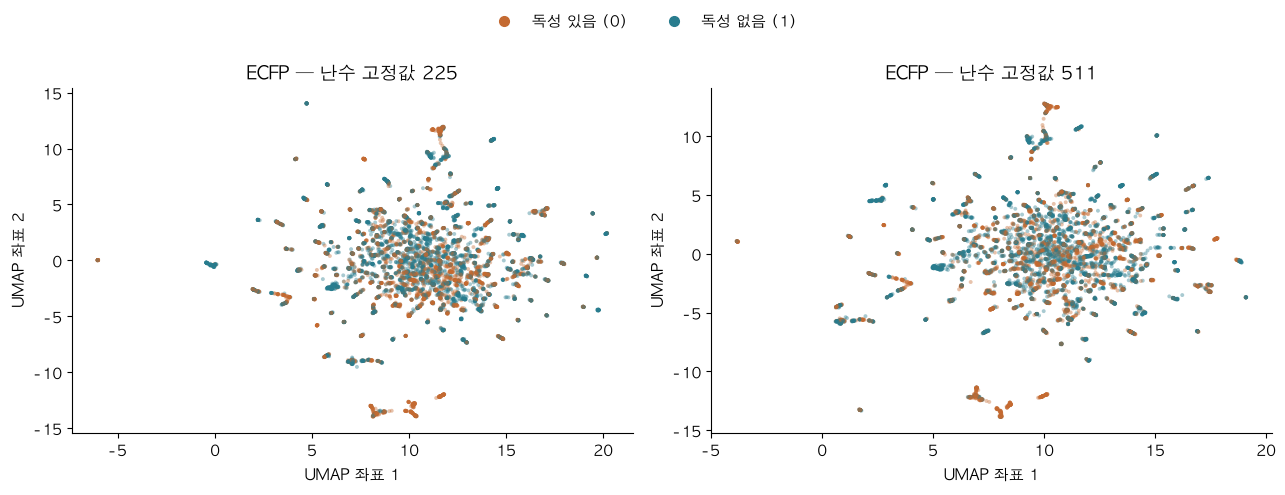

,입력 비트,제외한 상수 비트
표현,,
ECFP,1024,0
FCFP,1024,0
PTFP,975,49


In [16]:
# 그래프 셀을 따로 실행해도 한글 글꼴 적용
from pathlib import Path as _FontPath
from matplotlib import font_manager as _font_manager
_font_path = _FontPath('/System/Library/Fonts/Supplemental/AppleGothic.ttf')
if _font_path.is_file():
    _font_manager.fontManager.addfont(str(_font_path))
    plt.rcParams['font.family'] = _font_manager.FontProperties(fname=str(_font_path)).get_name()
else:
    _korean_fonts = [f for f in ['NanumGothic', 'Nanum Gothic', 'Malgun Gothic', 'AppleGothic']
                     if f in _font_manager.get_font_names()]
    if not _korean_fonts:
        raise RuntimeError('한글 글꼴 설치 후 커널 재시작 필요: NanumGothic 또는 Malgun Gothic')
    plt.rcParams['font.family'] = _korean_fonts[0]
plt.rcParams['axes.unicode_minus'] = False

alternate_mapper = umap.UMAP(n_components=2, metric='jaccard', n_neighbors=30,
                             min_dist=.15, random_state=511, n_jobs=1, low_memory=True)
alternate_coords = alternate_mapper.fit_transform(umap_inputs['ecfp'])
assert np.isfinite(alternate_coords).all()
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, coords, seed in zip(axes, [umap_maps['ecfp'], alternate_coords], [225, 511]):
    ax.scatter(coords[draw_order, 0], coords[draw_order, 1], c=point_colors,
               s=8, alpha=.4, linewidths=0, rasterized=True)
    ax.set(title=f'ECFP — 난수 고정값 {seed}', xlabel='UMAP 좌표 1', ylabel='UMAP 좌표 2')
fig.legend(handles=legend_handles, loc='upper center', ncol=2, frameon=False)
fig.tight_layout(rect=[0,0,1,.91]); plt.show()
display(pd.DataFrame(umap_metadata).set_index('표현'))

**왜 그렸는가?** UMAP은 계산 시작 조건에 따라 배치가 달라질 수 있어, 한 번의 그림에 과도한 의미를 두지 않기 위한 확인.

**어떻게 그렸는가?** ECFP 입력과 다른 설정은 유지하고 난수값만 225와 511로 변경. 위치나 방향의 일치보다 두 색이 섞이거나 모이는 양상을 비교.

**관찰한 점**: 두 그림 모두 중심부의 색 혼합과 일부 주변 묶음이 보이지만 세부 배치는 달라짐. 지도상의 특정 좌표나 방향 자체에 의미를 부여하지 않음.

**해석 한계**: 두 난수값만 비교한 제한적인 확인. 이웃 수, 거리 설정, 다른 데이터에서의 안정성까지 입증한 것은 아님. 2차원으로 줄이면서 정보가 손실되므로 색 분리만으로 예측 성능을 판단하지 않음.

방법 참고: [UMAP 설정과 이진 데이터 거리](https://umap-learn.readthedocs.io/en/latest/parameters.html)

## 7. 구간별 독성 비율: 분포의 이동을 판단 기준으로 연결

**확인할 질문**: 물성값이 커질수록 실제 독성 비율도 달라지는가? `clogp`와 `qed`를 같이 보면 새로운 조건이 나타나는가?

구조 중복을 제외한 **8,348개 분자** 기준. 아래의 독성 비율은 원래 label=0인 물질의 비율이며 예측 확률이 아님. 원본은 변경하지 않음.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import font_manager
from scipy import stats
from rdkit import Chem, RDLogger
from IPython.display import display

RDLogger.DisableLog('rdApp.*')
_font_file = Path('/System/Library/Fonts/Supplemental/AppleGothic.ttf')
if _font_file.is_file():
    font_manager.fontManager.addfont(str(_font_file))
    plt.rcParams['font.family'] = font_manager.FontProperties(fname=str(_font_file)).get_name()
else:
    _available = [f for f in ['NanumGothic','Nanum Gothic','Malgun Gothic','AppleGothic']
                  if f in font_manager.get_font_names()]
    if not _available:
        raise RuntimeError('한글 글꼴 설치 후 커널 재시작 필요')
    plt.rcParams['font.family'] = _available[0]
plt.rcParams['axes.unicode_minus'] = False
plt.rcParams.update({'font.size':11,'axes.spines.top':False,'axes.spines.right':False})

# Self-contained analysis section: reads source without changing earlier results.
source_df = pd.read_csv('Data/input_data/train.csv')
source_canonical = source_df.SMILES.map(
    lambda s: Chem.MolToSmiles(Chem.MolFromSmiles(s),isomericSmiles=True))
analysis_df = source_df.loc[~source_canonical.duplicated()].copy()
analysis_df['toxic'] = analysis_df.label.eq(0).astype(int)
properties_for_bins = ['MolWt','clogp','sa_score','qed']
base_rate = analysis_df.toxic.mean()
assert len(analysis_df)==8348
print(f'고유 분자 {len(analysis_df):,}개 / 전체 독성 비율 {base_rate:.2%}')

def wilson_interval(successes, totals, confidence=.95):
    successes=np.asarray(successes,dtype=float)
    totals=np.asarray(totals,dtype=float)
    assert (totals>0).all()
    z=stats.norm.ppf((1+confidence)/2)
    rate=successes/totals
    denominator=1+z*z/totals
    center=(rate+z*z/(2*totals))/denominator
    half=z*np.sqrt(rate*(1-rate)/totals+z*z/(4*totals*totals))/denominator
    return center-half,center+half

def holm_for_bins(pvalues):
    pvalues=np.asarray(pvalues,dtype=float)
    order=np.argsort(pvalues)
    sorted_adj=np.minimum(1,np.maximum.accumulate(
        (len(pvalues)-np.arange(len(pvalues)))*pvalues[order]))
    adjusted=np.empty_like(sorted_adj);adjusted[order]=sorted_adj
    return adjusted

고유 분자 8,348개 / 전체 독성 비율 45.60%


### 7-1. 물성별로 낮은 값부터 5구간 비교

**어떻게 나눴는가?** 각 특성을 값 순서대로 정렬해 표본 수가 비슷한 5구간으로 분리. 구간 너비가 같은 방식과 구분.

**그림 읽기**: 점은 구간의 독성 비율, 세로선은 비율의 불확실성을 나타내는 구간별 95% Wilson 신뢰구간. 점선은 전체 독성 비율. 가로축은 물성값이 낮은 구간에서 높은 구간 순서.

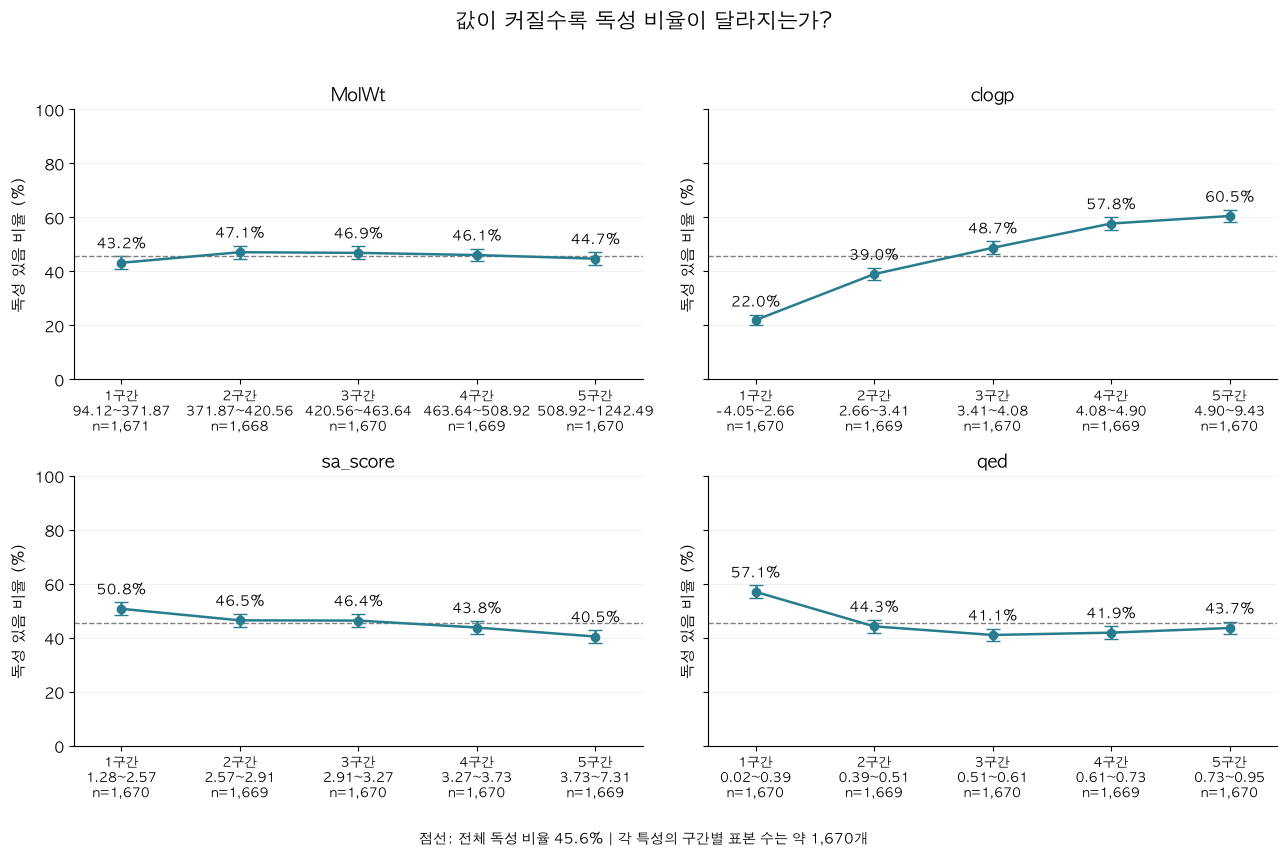

,가장 낮은 구간 독성률(%),가장 높은 구간 독성률(%),양끝 차이(%p),구간 차이 근거(보정 p<0.05)
특성,,,,
MolWt,43.21,44.73,1.52,False
clogp,21.98,60.54,38.56,True
sa_score,50.78,40.50,-10.28,True
qed,57.07,43.65,-13.41,True


In [2]:
bin_tables = {}
bin_edges = {}
bin_test_rows = []
for col in properties_for_bins:
    labels,edges=pd.qcut(analysis_df[col],q=5,labels=False,retbins=True,duplicates='drop')
    assert len(edges)==6
    table=analysis_df.groupby(labels,observed=True).toxic.agg(n='size',toxic_n='sum',rate='mean')
    table.index.name='bin'
    table['lo'],table['hi']=wilson_interval(table.toxic_n,table.n)
    table['lower_value']=edges[:-1];table['upper_value']=edges[1:]
    assert table.n.sum()==len(analysis_df)
    assert table.toxic_n.sum()==analysis_df.toxic.sum()
    counts=pd.crosstab(labels,analysis_df.toxic).reindex(columns=[0,1],fill_value=0)
    test=stats.chi2_contingency(counts,correction=False)
    assert test.expected_freq.min()>=5
    bin_test_rows.append({'특성':col,'p':float(test.pvalue),
                          'Cramers V':float(np.sqrt(test.statistic/len(analysis_df)))})
    bin_tables[col]=table;bin_edges[col]=edges
bin_tests=pd.DataFrame(bin_test_rows).set_index('특성')
bin_tests['Holm 보정 p']=holm_for_bins(bin_tests.p)

fig,axes=plt.subplots(2,2,figsize=(13,8.6),sharey=True)
for ax,col in zip(axes.flat,properties_for_bins):
    table=bin_tables[col]
    x=np.arange(1,6);rate=table.rate.to_numpy()*100
    ax.errorbar(x,rate,yerr=[rate-table.lo.to_numpy()*100,
                           table.hi.to_numpy()*100-rate],fmt='o-',
                color='#287C8E',capsize=5,lw=1.8,markersize=6)
    ax.axhline(base_rate*100,color='gray',linestyle='--',linewidth=1)
    for xi,yi,hi in zip(x,rate,table.hi):
        ax.text(xi,hi*100+3,f'{yi:.1f}%',ha='center',fontsize=10)
    tick_labels=[f'{i+1}구간\n{row.lower_value:.2f}~{row.upper_value:.2f}\nn={int(row.n):,}'
                 for i,(_,row) in enumerate(table.iterrows())]
    ax.set_xticks(x,labels=tick_labels,fontsize=9)
    ax.set(title=col,ylabel='독성 있음 비율 (%)',ylim=(0,100),xlim=(.6,5.4))
    ax.grid(axis='y',alpha=.15)
fig.suptitle('값이 커질수록 독성 비율이 달라지는가?',fontsize=15)
fig.text(.5,.01,f'점선: 전체 독성 비율 {base_rate:.1%} | 각 특성의 구간별 표본 수는 약 1,670개',
         ha='center',fontsize=10)
fig.tight_layout(rect=[0,.04,1,.96]);plt.show()

summary_rows=[]
for col in properties_for_bins:
    table=bin_tables[col]
    summary_rows.append({'특성':col,'가장 낮은 구간 독성률(%)':100*table.rate.iloc[0],
                         '가장 높은 구간 독성률(%)':100*table.rate.iloc[-1],
                         '양끝 차이(%p)':100*(table.rate.iloc[-1]-table.rate.iloc[0]),
                         '구간 차이 근거(보정 p<0.05)':bool(bin_tests.loc[col,'Holm 보정 p']<.05)})
display(pd.DataFrame(summary_rows).set_index('특성').round(2))

**왜 그렸는가?** 집단의 평균이 다르다는 관찰을 넘어, 물성값이 증가할 때 독성 비율도 일관되게 달라지는지 확인.

**결과 해석**

| 특성 | 낮은 구간 → 높은 구간의 독성 비율 | 의미 |
| --- | --- | --- |
| `clogp` | **22.0% → 39.0% → 48.7% → 57.8% → 60.5%** | 값이 높은 구간일수록 독성 비율이 증가. 가장 뚜렷한 순서 정보 |
| `MolWt` | 43.2% → 47.1% → 46.9% → 46.1% → 44.7% | 큰 차이나 일정한 증가 방향이 보이지 않음 |
| `sa_score` | 50.8% → 46.5% → 46.4% → 43.8% → 40.5% | 대체로 감소하지만 clogp보다 변화 폭이 작음 |
| `qed` | 57.1% → 44.3% → 41.1% → 41.9% → 43.7% | 가장 낮은 구간의 독성률이 높고, 이후에는 계속 감소하지 않음 |

`clogp` 양끝 구간은 약 **38.6%p 차이**. 그래도 가장 낮은 구간에서 22.0%가 독성이므로 안전 판정 기준으로 바로 사용 불가.

표의 ‘구간 차이 근거’는 카이제곱 검정 후 네 특성의 p값을 Holm 보정한 결과. 차이가 있는지를 확인할 뿐, 값 증가에 따른 방향이나 인과관계를 입증하는 검정은 아님.

### 7-2. clogp와 qed를 함께 나눈 9개 구역

**왜 그렸는가?** ‘qed가 높으면 독성이 낮다’는 관계가 비슷한 clogp 범위에서도 유지되는지 확인.

**어떻게 나눴는가?** 두 특성을 각각 표본 수가 비슷한 낮음, 중간, 높음의 세 구간으로 나눈 뒤 조합. 각 칸의 분자 수는 서로 다름. 독성 정답으로 경계값을 선택하지 않음.

앞 그림은 5구간, 이 그림은 3구간 기준이므로 ‘낮음’의 범위가 다름. 예를 들어 clogp 낮음의 22%와 28%는 서로 다른 범위의 분자를 집계한 결과.

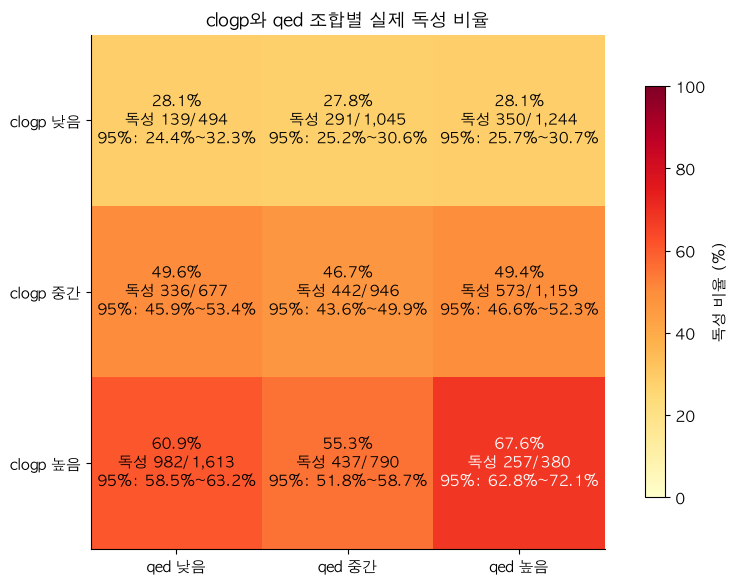

,낮음,중간,높음
clogp,-4.049~3.186,3.186~4.329,4.329~9.429
qed,0.024~0.472,0.472~0.649,0.649~0.947


표시된 경계는 소수점 3자리 반올림. 정확한 분류는 qcut 결과 사용.


In [3]:
levels=['낮음','중간','높음']
clogp_band,clogp_edges=pd.qcut(analysis_df.clogp,3,labels=levels,retbins=True)
qed_band,qed_edges=pd.qcut(analysis_df.qed,3,labels=levels,retbins=True)
grid_source=analysis_df[['toxic']].assign(clogp_band=clogp_band,qed_band=qed_band)
grid_table=(grid_source.groupby(['clogp_band','qed_band'],observed=True)
            .toxic.agg(n='size',toxic_n='sum',rate='mean'))
grid_table['lo'],grid_table['hi']=wilson_interval(grid_table.toxic_n,grid_table.n)
assert len(grid_table)==9
assert grid_table.n.sum()==len(analysis_df)
assert grid_table.toxic_n.sum()==analysis_df.toxic.sum()
rate_grid=grid_table.rate.unstack('qed_band').reindex(index=levels,columns=levels)
count_grid=grid_table.n.unstack('qed_band').reindex(index=levels,columns=levels)
fig,ax=plt.subplots(figsize=(8.5,6))
im=ax.imshow(rate_grid.to_numpy()*100,cmap='YlOrRd',vmin=0,vmax=100)
for i,cl in enumerate(levels):
    for j,qe in enumerate(levels):
        row=grid_table.loc[(cl,qe)]
        ax.text(j,i,f'{row.rate:.1%}\n독성 {int(row.toxic_n):,}/{int(row.n):,}\n95%: {row.lo:.1%}~{row.hi:.1%}',
                ha='center',va='center',fontsize=11,
                color='white' if row.rate>.62 else 'black')
ax.set_xticks(range(3),labels=[f'qed {x}' for x in levels])
ax.set_yticks(range(3),labels=[f'clogp {x}' for x in levels])
ax.set_title('clogp와 qed 조합별 실제 독성 비율')
fig.colorbar(im,ax=ax,label='독성 비율 (%)',shrink=.8)
fig.tight_layout();plt.show()
edge_table=pd.DataFrame({
    '낮음':[f'{clogp_edges[0]:.3f}~{clogp_edges[1]:.3f}',f'{qed_edges[0]:.3f}~{qed_edges[1]:.3f}'],
    '중간':[f'{clogp_edges[1]:.3f}~{clogp_edges[2]:.3f}',f'{qed_edges[1]:.3f}~{qed_edges[2]:.3f}'],
    '높음':[f'{clogp_edges[2]:.3f}~{clogp_edges[3]:.3f}',f'{qed_edges[2]:.3f}~{qed_edges[3]:.3f}']},
    index=['clogp','qed'])
display(edge_table)
print('표시된 경계는 소수점 3자리 반올림. 정확한 분류는 qcut 결과 사용.')

**결과 해석**

- **clogp 낮음**: qed가 낮아도, 중간이어도, 높아도 독성률이 약 **28%**로 비슷함
- **clogp 중간**: 세 qed 구역에서 약 **47~50%**
- **clogp 높음**: 세 qed 구역에서 약 **55~68%**. qed가 높다고 독성률이 낮아지지 않음

따라서 이 구간 구분에서는 **qed보다 clogp에 따른 차이가 더 일관적**. 단독으로 본 qed의 경향에는 다른 물성의 구성이 함께 반영됐을 가능성 존재. 이것만으로 원인이나 두 특성의 상호작용을 확정한 것은 아님.

가장 높은 칸은 clogp 높음 + qed 높음으로 **67.6%**, 380개 중 257개가 독성. 표본 수와 불확실성을 함께 확인해야 하며, 이 구역을 곧바로 독성 판정 규칙으로 쓰지는 않음.

### 7-3. 같은 qed 범위에서도 clogp 경향이 유지되는가?

9개 구역을 선 그래프로 다시 비교. qed가 비슷한 분자 안에서도 clogp가 높아질 때 독성 비율이 높아지는지 확인.

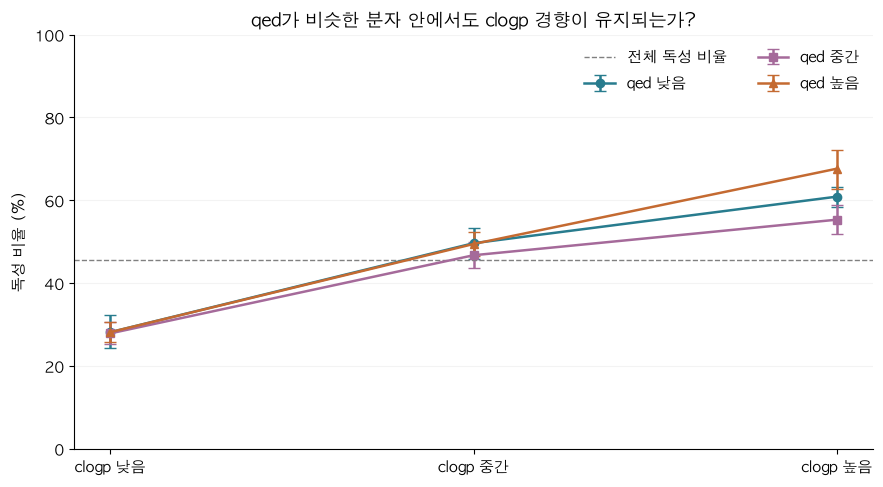

9개 구역의 표본 수: 최소 380개, 최대 1,613개


In [4]:
fig,ax=plt.subplots(figsize=(9,5))
line_colors=['#287C8E','#A56A9A','#C46A31']
markers=['o','s','^']
for qe,color,marker in zip(levels,line_colors,markers):
    rows=grid_table.xs(qe,level='qed_band').reindex(levels)
    y=rows.rate.to_numpy()*100
    ax.errorbar(np.arange(3),y,yerr=[y-rows.lo.to_numpy()*100,rows.hi.to_numpy()*100-y],
                fmt=marker+'-',color=color,capsize=4,label=f'qed {qe}',linewidth=1.8)
ax.axhline(base_rate*100,color='gray',linestyle='--',linewidth=1,label='전체 독성 비율')
ax.set_xticks(np.arange(3),labels=['clogp 낮음','clogp 중간','clogp 높음'])
ax.set(title='qed가 비슷한 분자 안에서도 clogp 경향이 유지되는가?',
       ylabel='독성 비율 (%)',ylim=(0,100))
ax.legend(frameon=False,ncol=2)
ax.grid(axis='y',alpha=.15)
fig.tight_layout();plt.show()
# Verify plotted estimates remain inside their reported Wilson intervals.
assert (grid_table.lo<=grid_table.rate).all() and (grid_table.rate<=grid_table.hi).all()
assert grid_table.n.min()>=300
print(f'9개 구역의 표본 수: 최소 {int(grid_table.n.min()):,}개, 최대 {int(grid_table.n.max()):,}개')

**왜 이렇게 확인했는가?** 단순히 qed가 다른 집단끼리 비교하면 clogp 구성 차이를 함께 볼 수 있기 때문. 같은 qed 범위 안에서 방향을 다시 확인.

**결과**: 세 qed 범위 모두 clogp가 높아질수록 독성 비율 증가. 현재 자료에서는 clogp를 우선 확인할 물성 신호로 볼 근거 강화.

**현재 고를 판단**

1. clogp를 우선적인 추가 검토 기준 후보로 유지
2. qed가 높다는 이유만으로 안전하다고 판단하지 않기
3. sa_score는 보조 후보로, MolWt는 단독 기준으로 과대해석하지 않기

**범위와 한계**: 전부 같은 학습 데이터 안에서 확인한 탐색 결과. 구간과 비율은 이 표본에 따른 값이며 독립 데이터에서 재현된 규칙은 아님. 그래프의 구간은 각각의 95% Wilson 구간으로, 모든 칸을 동시에 보장하거나 칸별 차이를 검정한 결과와 구분. 이 분석은 인과관계나 모든 물성의 영향을 통제한 결과도 아님.

구조 지도에서의 거리 가설은 별도 단계에서 **원래 Fingerprint 유사도**로 확인할 대상. 이번 절에서는 물성 구간 분석에 집중.

## 8. 데이터 전처리 분석: 입력 정보와 검증 방식 점검

받은 `EDA_report.html`에서 현재 노트에 없던 분석을 추가. 보고서 내용을 옮기기보다 현재 `train.csv`에서 다시 계산한 결과로 확인.

```text
중복 컬럼 → 같은 입력·다른 정답 → 입체화학 표현 비교
      → 물성의 조건부 관계 → 실제 구조 이웃 → 골격별 안정성 → 행 순서
```

**원본 변경 및 자동 삭제 없음.** 전체 8,349행은 입력 충돌과 행 순서 점검에 사용하고, 관계 분석과 이웃 분석은 동일 분자 중복을 제외한 8,348개 분자 사용.

추가 패키지: `statsmodels`(물성의 조건부 연관성), `scikit-learn`(골격 그룹 분할). 수식보다 처리 판단과 결과 의미 중심으로 설명.

In [1]:
from pathlib import Path
from collections import defaultdict
import hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import font_manager
from IPython.display import display
from scipy import stats
from rdkit import Chem, RDLogger
from rdkit.Chem import rdFingerprintGenerator, Draw
from rdkit.Chem.Scaffolds import MurckoScaffold

RDLogger.DisableLog('rdApp.*')
font_file=Path('/System/Library/Fonts/Supplemental/AppleGothic.ttf')
if font_file.is_file():
    font_manager.fontManager.addfont(str(font_file))
    plt.rcParams['font.family']=font_manager.FontProperties(fname=str(font_file)).get_name()
else:
    available=[f for f in ['NanumGothic','Nanum Gothic','Malgun Gothic','AppleGothic']
               if f in font_manager.get_font_names()]
    if not available: raise RuntimeError('한글 글꼴 설치 후 커널 재시작 필요')
    plt.rcParams['font.family']=available[0]
plt.rcParams.update({'axes.unicode_minus':False,'font.size':11,
                     'axes.spines.top':False,'axes.spines.right':False})
pre_path=Path('Data/input_data/train.csv')
pre_raw=pd.read_csv(pre_path)
pre_props=['MolWt','clogp','sa_score','qed']
pre_fps=[c for c in pre_raw if c.startswith(('ecfp_','fcfp_','ptfp_'))]
pre_mols=[Chem.MolFromSmiles(s) for s in pre_raw.SMILES]
assert all(m is not None for m in pre_mols)
pre_canonical=np.array([Chem.MolToSmiles(m,isomericSmiles=True) for m in pre_mols])
pre_unique_mask=~pd.Series(pre_canonical).duplicated().to_numpy()
pre_unique=pre_raw.loc[pre_unique_mask].copy()
pre_unique['toxic']=pre_unique.label.eq(0).astype(int)
pre_unique_mols=[m for m,keep in zip(pre_mols,pre_unique_mask) if keep]
pre_labels=pre_raw.label.to_numpy()
pre_bits=pre_raw[pre_fps].to_numpy(dtype=np.uint8)
pre_packed=np.packbits(pre_bits,axis=1)
pre_properties=pre_raw[pre_props].to_numpy(dtype=np.float64)
pre_properties[pre_properties==0]=0.0
pre_full_keys=[a.tobytes()+b.tobytes() for a,b in zip(pre_packed,pre_properties)]
print(f'원본 {len(pre_raw):,}행 / 고유 분자 {len(pre_unique):,}개')
print('입력 SHA-256:',hashlib.sha256(pre_path.read_bytes()).hexdigest())

def pre_holm(pvalues):
    pvalues=np.asarray(pvalues,dtype=float);order=np.argsort(pvalues)
    adj=np.minimum(1,np.maximum.accumulate((len(pvalues)-np.arange(len(pvalues)))*pvalues[order]))
    result=np.empty_like(adj);result[order]=adj;return result

def pre_wilson(k,n):
    k=np.asarray(k,dtype=float);n=np.asarray(n,dtype=float)
    z=stats.norm.ppf(.975);p=k/n;den=1+z*z/n
    center=(p+z*z/(2*n))/den
    half=z*np.sqrt(p*(1-p)/n+z*z/(4*n*n))/den
    return center-half,center+half

def pre_conflicts(keys,labels):
    groups=defaultdict(list)
    for i,key in enumerate(keys):groups[key].append(i)
    mixed=[ids for ids in groups.values() if len(set(labels[ids]))>1]
    result={'충돌 그룹':len(mixed),'해당 행':sum(map(len,mixed)),
            '동일 입력 제약의 최소 오류':sum(min(np.count_nonzero(labels[ids]==0),
                                           np.count_nonzero(labels[ids]==1)) for ids in mixed)}
    return mixed,result

원본 8,349행 / 고유 분자 8,348개
입력 SHA-256: cb7118a9533e36d81cdb4aa2e9318e9fa0b80faa70d132d7d3b2009e81fca5d8


### 8-1. 상수뿐 아니라 같은 값의 컬럼도 있는가?

**왜 확인하는가?** 컬럼 수가 많아도 모든 값이 같은 컬럼이나 서로 똑같은 컬럼은 추가 구분 정보를 주지 않기 때문.

**방법**: Fingerprint 열 전체의 0/1 패턴을 정확히 비교. 상수 열을 먼저 뺀 뒤 나머지 중복을 세어 이중 집계 방지.

,단계,컬럼 수
0,전체 Fingerprint,3072
1,상수 제외 후,3023
2,남은 중복 패턴 제외 후,2965


상수 포함 중복 추가 컬럼: 106
상수 제외 후 중복 추가 컬럼: 58


,중복 컬럼,대표 컬럼
0,ptfp_39,ptfp_28
1,ptfp_46,ptfp_41
2,ptfp_86,ptfp_28
3,ptfp_108,ptfp_41
4,ptfp_179,ptfp_28


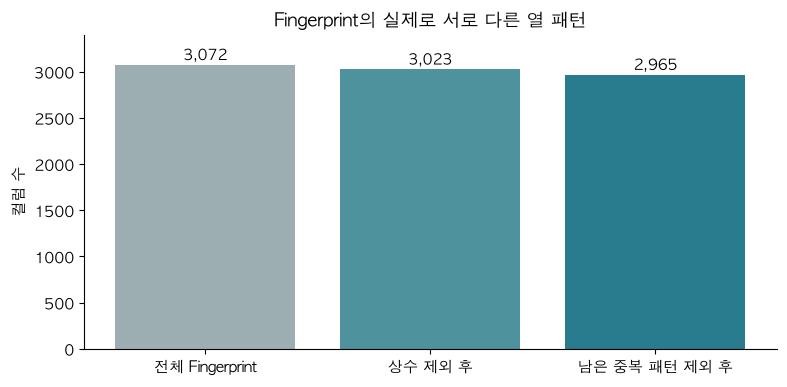

In [2]:
pre_column_patterns=np.packbits(pre_bits,axis=0).T
pre_constant=(pre_bits.min(axis=0)==pre_bits.max(axis=0))
all_patterns=set();variable_patterns={};pre_duplicate_mapping=[]
for j,col in enumerate(pre_fps):
    key=pre_column_patterns[j].tobytes()
    all_patterns.add(key)
    if pre_constant[j]:continue
    if key in variable_patterns:
        pre_duplicate_mapping.append({'중복 컬럼':col,'대표 컬럼':variable_patterns[key]})
    else:variable_patterns[key]=col
pre_column_summary=pd.DataFrame({
    '단계':['전체 Fingerprint','상수 제외 후','남은 중복 패턴 제외 후'],
    '컬럼 수':[len(pre_fps),int((~pre_constant).sum()),len(variable_patterns)]})
display(pre_column_summary)
print('상수 포함 중복 추가 컬럼:',len(pre_fps)-len(all_patterns))
print('상수 제외 후 중복 추가 컬럼:',len(pre_duplicate_mapping))
display(pd.DataFrame(pre_duplicate_mapping).head(5))
fig,ax=plt.subplots(figsize=(8,4))
bars=ax.bar(pre_column_summary['단계'],pre_column_summary['컬럼 수'],color=['#9DAEB3','#4D929C','#287C8E'])
for bar,count in zip(bars,pre_column_summary['컬럼 수']):
    ax.text(bar.get_x()+bar.get_width()/2,count,f'{count:,}',ha='center',va='bottom')
ax.set(title='Fingerprint의 실제로 서로 다른 열 패턴',ylabel='컬럼 수',ylim=(0,3400))
fig.tight_layout();plt.show()
# Recheck every proposed duplicate column against the original values.
assert all(np.array_equal(pre_raw[item['중복 컬럼']].to_numpy(),
                          pre_raw[item['대표 컬럼']].to_numpy()) for item in pre_duplicate_mapping)


**해석**: Fingerprint 3,072개에서 상수 49개를 빼면 3,023개. 여기서 값이 똑같은 비상수 추가 열 58개를 정리하면 **2,965개의 서로 다른 비상수 열 패턴**이 남음.

상수 포함 중복 추가 열 106개에는 상수 열의 반복도 포함되므로 상수 49개와 단순 합산하면 이중 집계.

**처리 방향**: 제거 목록은 학습 부분에서 결정하고 검증·예측 데이터에 동일 적용. 현재 표본에서 같았던 열이 새로운 분자에서도 항상 같다는 보장은 없음.

### 8-2. 수치 입력은 같은데 정답이 다른가?

**왜 확인하는가?** 서로 다른 분자가 같은 숫자로 표현되면, 그 숫자만으로 서로 다른 정답을 모두 구분할 수 없기 때문.

**방법**: ECFP만, Fingerprint 전체, 물성까지 포함한 전체 숫자 입력을 각각 정확하게 묶고 label 혼합 여부 확인. SMILES 자체는 묶음 기준에서 제외.

,충돌 그룹,해당 행,동일 입력 제약의 최소 오류
입력 기준,,,
"ECFP 1,024개",36,79,37
"Fingerprint 3,072개",34,75,35
"숫자 입력 전체 3,076개",33,73,34


,CSV 행 번호,SMILES,label
98,100,CN1CC=CCC(C1)c2ccc(Cl)c(Cl)c2,0
99,101,CN1CC=CC[C@@H](C1)c2ccc(Cl)c(Cl)c2,1


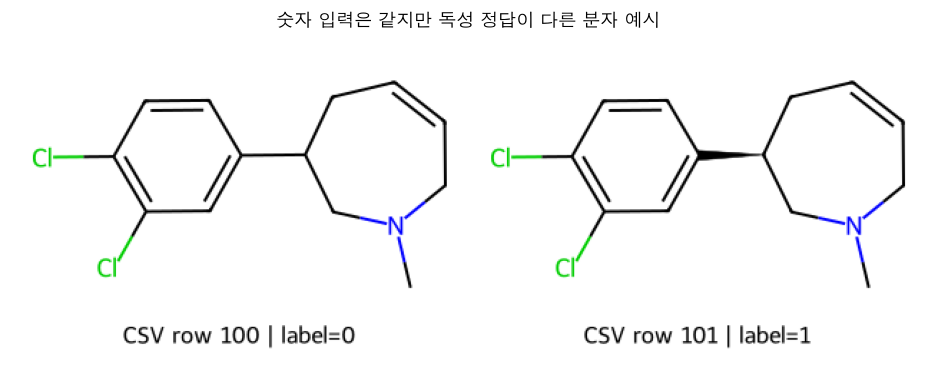

In [3]:
pre_collision_rows=[]
pre_mixed_all=[]
for name,keys in [
    ('ECFP 1,024개',[row[:128].tobytes() for row in pre_packed]),
    ('Fingerprint 3,072개',[row.tobytes() for row in pre_packed]),
    ('숫자 입력 전체 3,076개',pre_full_keys)]:
    mixed,result=pre_conflicts(keys,pre_labels)
    pre_collision_rows.append({'입력 기준':name,**result})
    if name.startswith('숫자'):pre_mixed_all=mixed
pre_collision_table=pd.DataFrame(pre_collision_rows).set_index('입력 기준')
display(pre_collision_table)
example_ids=pre_mixed_all[0]
pre_example=pre_raw.iloc[example_ids][['SMILES','label']].copy()
pre_example.insert(0,'CSV 행 번호',np.array(example_ids)+2)
display(pre_example)
from rdkit.Chem.Draw import rdMolDraw2D
from PIL import Image as PILImage
import io
painter=rdMolDraw2D.MolDraw2DCairo(320*len(example_ids),230,320,230)
painter.DrawMolecules([pre_mols[i] for i in example_ids],
                      legends=[f'CSV row {i+2} | label={pre_labels[i]}' for i in example_ids])
painter.FinishDrawing()
img=PILImage.open(io.BytesIO(painter.GetDrawingText()))
fig,ax=plt.subplots(figsize=(10,3.8));ax.imshow(img);ax.axis('off')
ax.set_title('숫자 입력은 같지만 독성 정답이 다른 분자 예시');fig.tight_layout();plt.show()
# Keys must represent genuinely identical provided numeric inputs.
for ids in pre_mixed_all:
    assert np.array_equal(pre_bits[ids],np.repeat(pre_bits[ids[:1]],len(ids),axis=0))
    assert np.array_equal(pre_properties[ids],np.repeat(pre_properties[ids[:1]],len(ids),axis=0))


**해석**: 전체 숫자가 같은데도 정답이 다른 그룹 **33개, 총 73행** 확인. 같은 입력에 같은 답을 내는 분류기는 이 표본에서 최소 **34행**을 동시에 맞힐 수 없음.

앞서 ‘같은 분자의 정답 충돌 없음’과 다른 기준의 점검. **분자는 다르지만 제공된 숫자가 같을 수 있음.** 이 결과는 일반화 성능이나 F1 상한이 아님.

**처리 방향**: 자동 삭제 대신 분자 표현에서 빠진 정보, 실험 조건, 정답 생성 기준 확인. 대표 예시는 입체화학 미지정과 지정의 차이도 포함할 수 있어 서로 다른 입체이성질체라고 일괄 단정 불가.

### 8-3. 입체화학을 추가하면 입력 충돌이 줄어드는가?

**입체화학**: 원자 연결 외에 공간 배치를 나타내는 정보. 같은 연결 구조라도 SMILES의 배치 지정이 다를 수 있음.

**방법**: 같은 2,048비트 Morgan 표현에서 입체화학 사용 여부만 바꾸어 비교. 반경은 2, 3, 4로 각각 확인. 기존 수치 입력에 새 표현을 덧붙였을 때 남는 label 혼합 그룹 집계. 반경은 결합을 따라 살피는 범위이며 실제 3차원 거리와 구분.

,반경,입체화학 반영,남은 충돌 그룹,해당 행
0,2,False,33,73
1,2,True,6,12
2,3,False,33,73
3,3,True,5,10
4,4,False,33,73
5,4,True,4,8


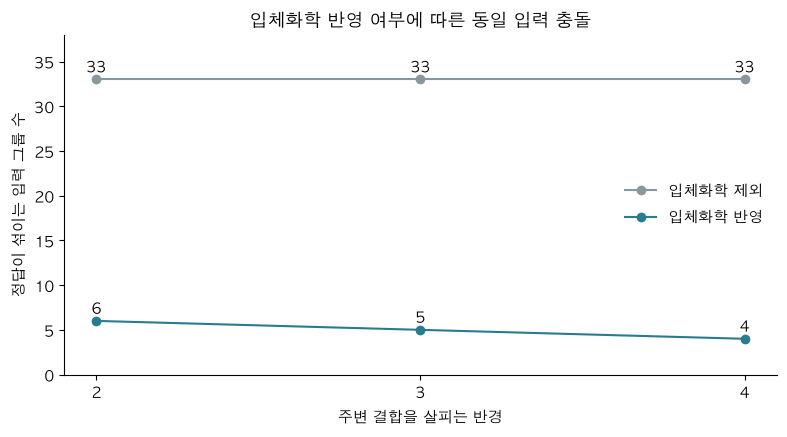

In [4]:
pre_stereo_rows=[]
for radius in [2,3,4]:
    for chirality in [False,True]:
        generator=rdFingerprintGenerator.GetMorganGenerator(
            radius=radius,fpSize=2048,includeChirality=chirality)
        remaining=[]
        # New features can only split existing groups: analyze the original mixed groups.
        for ids in pre_mixed_all:
            subgroups=defaultdict(list)
            for i in ids:
                subgroups[generator.GetFingerprint(pre_mols[i]).ToBitString()].append(i)
            remaining.extend(v for v in subgroups.values() if len(set(pre_labels[v]))>1)
        pre_stereo_rows.append({'반경':radius,'입체화학 반영':chirality,
                                '남은 충돌 그룹':len(remaining),'해당 행':sum(map(len,remaining))})
pre_stereo_table=pd.DataFrame(pre_stereo_rows)
display(pre_stereo_table)
fig,ax=plt.subplots(figsize=(8,4.5))
for flag,color,name in [(False,'#87999F','입체화학 제외'),(True,'#287C8E','입체화학 반영')]:
    subset=pre_stereo_table.loc[pre_stereo_table['입체화학 반영'].eq(flag)]
    ax.plot(subset['반경'],subset['남은 충돌 그룹'],'o-',color=color,label=name)
    for x,y in zip(subset['반경'],subset['남은 충돌 그룹']):ax.text(x,y+.8,str(y),ha='center')
ax.set(title='입체화학 반영 여부에 따른 동일 입력 충돌',xlabel='주변 결합을 살피는 반경',
       ylabel='정답이 섞이는 입력 그룹 수',ylim=(0,38));ax.set_xticks([2,3,4]);ax.legend(frameon=False)
fig.tight_layout();plt.show()

**해석**: 입체화학을 끄면 충돌 그룹은 33개로 유지. 켜면 반경 2에서 **6개**, 반경 4에서 **4개**로 감소. 기존에 같던 입력을 더 잘 구분할 여지가 생긴 결과이며, 예측 성능 향상까지 확인한 것은 아님.

**처리 방향**: 입체화학 보존 표현을 추가 후보로 검토. SMILES에 기록되지 않은 배치를 복원하는 방법은 아니며, 공간 배치가 정답 차이의 원인이라는 증거와도 구분.

### 8-4. 다른 물성을 함께 고려해도 관계가 남는가?

**왜 확인하는가?** 서로 관련된 물성을 각각 보면 다른 물성의 영향을 함께 볼 수 있기 때문. 분자량과 qed의 관계처럼 겹치는 정보를 고려할 필요.

**방법**: 물성 네 개를 동시에 넣은 회귀로 조건부 연관성 추정. 단위 차이를 맞추고, 같은 중심 골격의 분자끼리 비슷할 가능성을 고려한 불확실성 계산. 예측 점수 측정이 아닌 관계 분석.

**오즈비**: 1보다 크면 독성 쪽, 작으면 비독성 쪽의 조건부 연관. 확률이 그 배수로 변한다는 의미는 아님. 구간에 1이 포함되면 해당 조건부 관계의 근거가 명확하지 않음.

,오즈비,95% 하한,95% 상한
물성,,,
MolWt,0.722,0.633,0.824
clogp,1.950,1.764,2.156
sa_score,1.037,0.923,1.165
qed,0.889,0.783,1.008


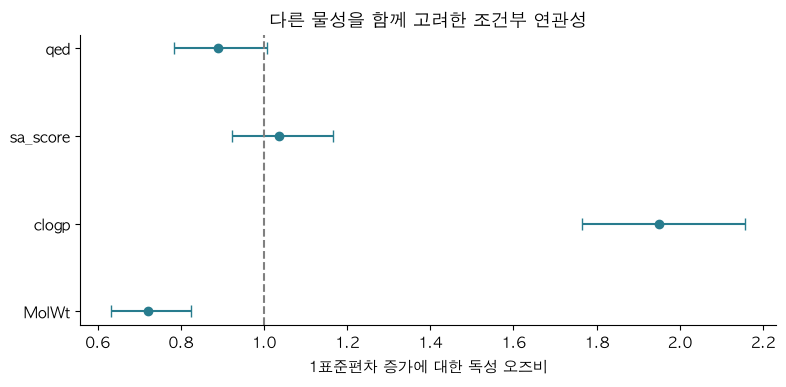

In [5]:
import statsmodels.api as sm

pre_scaffolds_raw=np.array([MurckoScaffold.MurckoScaffoldSmiles(mol=m,includeChirality=False)
                            for m in pre_mols])
pre_scaffolds=pre_scaffolds_raw[pre_unique_mask]
pre_z=(pre_unique[pre_props]-pre_unique[pre_props].mean())/pre_unique[pre_props].std(ddof=0)
pre_X=sm.add_constant(pre_z)
pre_fit=sm.GLM(pre_unique.toxic.to_numpy(),pre_X,family=sm.families.Binomial()).fit(
    cov_type='cluster',cov_kwds={'groups':pre_scaffolds})
pre_ci=pre_fit.conf_int().loc[pre_props]
pre_or_table=pd.DataFrame({'물성':pre_props,
    '오즈비':np.exp(pre_fit.params.loc[pre_props]).to_numpy(),
    '95% 하한':np.exp(pre_ci[0]).to_numpy(),'95% 상한':np.exp(pre_ci[1]).to_numpy(),
    'p':pre_fit.pvalues.loc[pre_props].to_numpy()}).set_index('물성')
assert pre_fit.converged
assert np.isfinite(pre_or_table.to_numpy()).all()
display(pre_or_table[['오즈비','95% 하한','95% 상한']].round(3))
fig,ax=plt.subplots(figsize=(8,4))
for i,(col,row) in enumerate(pre_or_table.iterrows()):
    ax.errorbar(row['오즈비'],i,xerr=[[row['오즈비']-row['95% 하한']],
                                   [row['95% 상한']-row['오즈비']]],fmt='o',capsize=4,color='#287C8E')
ax.axvline(1,color='gray',linestyle='--');ax.set_yticks(range(4),labels=pre_props)
ax.set(title='다른 물성을 함께 고려한 조건부 연관성',xlabel='1표준편차 증가에 대한 독성 오즈비')
fig.tight_layout();plt.show()

**해석**

- `clogp`: 오즈비 **1.95**, 구간 **1.76~2.16** → 다른 세 물성을 함께 고려해도 독성 쪽 연관성 유지
- `MolWt`: 오즈비 **0.72**, 구간 **0.63~0.82** → 단독 비교에서는 약했지만 조건부 관계가 관찰됨. 이 값만으로 보호 작용이 있다는 뜻은 아님
- `sa_score`: **1.04**, 구간 **0.92~1.17**. `qed`: **0.89**, 구간 **0.78~1.01** → 두 구간 모두 1을 포함해 현재 모형에서 개별 관계의 근거가 명확하지 않음

**전처리 판단**: 단독 p값이나 평균 차이만으로 물성을 버리면 놓치는 정보가 있을 수 있음.

**한계**: 회귀의 관계 형태 가정과 미측정 변수가 남아 있음. 골격 보정도 모든 분자 유사성을 제거하는 방법은 아니므로 인과효과로 해석 불가. 받은 보고서는 원본 8,349행, 여기서는 중복 제외 8,348개 분자 사용으로 수치의 소폭 차이 가능.

### 8-5. 원래 Fingerprint에서 가까운 분자의 정답은 같은가?

**왜 확인하는가?** UMAP 지도의 중심이나 원점 거리는 독성 기준이 아니므로, 원래 구조 정보의 유사도로 비교.

**방법**: 중복 제거 후 8,348개 분자의 ECFP에 Tanimoto 유사도 적용. 자기 자신을 제외한 최근접 분자 1개 선정. 유사도 1은 ECFP가 같다는 뜻이며 실제 분자가 같다는 뜻과 구분. 최근접 동률에서는 원자료에서 먼저 나온 분자를 선택하고 동률의 영향도 집계.

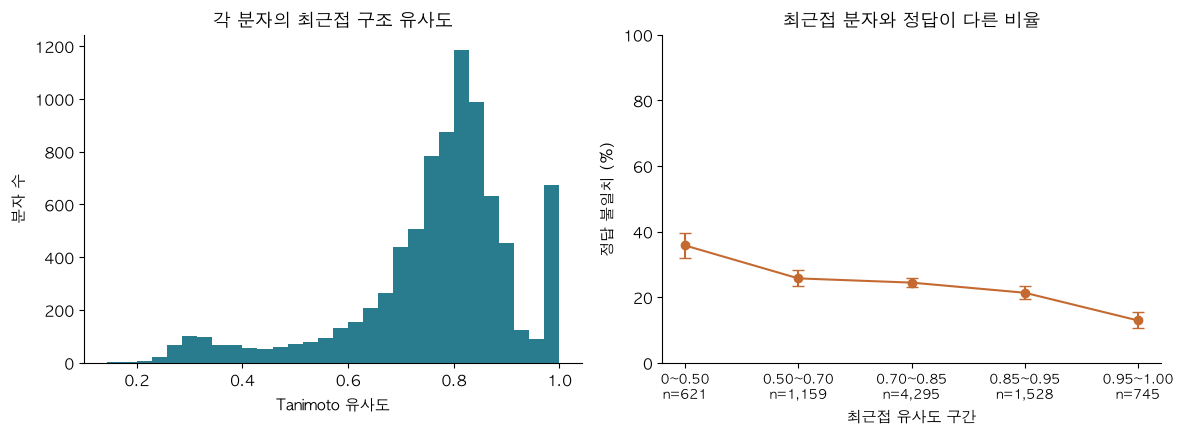

,분자 수,정답 불일치 수,불일치 비율,95% 하한,95% 상한
similarity,,,,,
0~0.50,621,222,0.3575,0.3208,0.3960
0.50~0.70,1159,298,0.2571,0.2328,0.2831
0.70~0.85,4295,1049,0.2442,0.2316,0.2573
0.85~0.95,1528,326,0.2134,0.1935,0.2346
0.95~1.00,745,96,0.1289,0.1067,0.1548


최근접 유사도 중앙값: 0.797
최근접 동률이 있는 분자: 799개
동률 이웃들 사이에 정답이 섞인 분자: 143개


무작위 5개 분자의 최근접 결과를 RDKit 직접 계산과 대조 완료


In [6]:
pre_ecfp_columns=[c for c in pre_fps if c.startswith('ecfp_')]
pre_ecfp=pre_unique[pre_ecfp_columns].to_numpy(dtype=np.uint8)
# 1,024 bits -> 16 uint64 words. Process in blocks to avoid storing a full distance matrix.
pre_ecfp_u64=np.ascontiguousarray(np.packbits(pre_ecfp,axis=1)).view(np.uint64)
pre_active=pre_ecfp.sum(axis=1,dtype=np.int64)
pre_toxic=pre_unique.toxic.to_numpy()
pre_n=len(pre_unique)
pre_nearest_index=np.empty(pre_n,dtype=int)
pre_nearest_similarity=np.empty(pre_n)
pre_tie_count=np.empty(pre_n,dtype=int)
pre_mixed_ties=np.empty(pre_n,dtype=bool)
for begin in range(0,pre_n,64):
    end=min(begin+64,pre_n)
    intersections=np.bitwise_count(pre_ecfp_u64[begin:end,None,:]&pre_ecfp_u64[None,:,:]).sum(axis=2)
    unions=pre_active[begin:end,None]+pre_active[None,:]-intersections
    similarities=np.divide(intersections,unions,out=np.zeros_like(intersections,dtype=float),where=unions>0)
    similarities[np.arange(end-begin),np.arange(begin,end)]=-1
    nearest=similarities.argmax(axis=1)
    maxima=similarities[np.arange(end-begin),nearest]
    tied=np.isclose(similarities,maxima[:,None],rtol=0,atol=1e-12)
    pre_nearest_index[begin:end]=nearest
    pre_nearest_similarity[begin:end]=maxima
    pre_tie_count[begin:end]=tied.sum(axis=1)
    pre_mixed_ties[begin:end]=tied[:,pre_toxic==1].any(axis=1)&tied[:,pre_toxic==0].any(axis=1)
assert (pre_nearest_index!=np.arange(pre_n)).all()
pre_disagree=pre_toxic!=pre_toxic[pre_nearest_index]
pre_nearest=pd.DataFrame({'similarity':pre_nearest_similarity,'disagree':pre_disagree,
                          'tied_neighbors':pre_tie_count,'mixed_label_ties':pre_mixed_ties})
pre_similarity_ranges=pd.cut(pre_nearest.similarity,[0,.5,.7,.85,.95,1.000001],
    include_lowest=True,right=False,labels=['0~0.50','0.50~0.70','0.70~0.85','0.85~0.95','0.95~1.00'])
pre_neighbor_table=pre_nearest.groupby(pre_similarity_ranges,observed=True).disagree.agg(
    n='size',different='sum',rate='mean')
pre_neighbor_table['lo'],pre_neighbor_table['hi']=pre_wilson(pre_neighbor_table.different,pre_neighbor_table.n)
assert pre_neighbor_table.n.sum()==pre_n
fig,axes=plt.subplots(1,2,figsize=(12,4.5))
axes[0].hist(pre_nearest_similarity,bins=30,color='#287C8E')
axes[0].set(title='각 분자의 최근접 구조 유사도',xlabel='Tanimoto 유사도',ylabel='분자 수')
x=np.arange(len(pre_neighbor_table));rate=pre_neighbor_table.rate.to_numpy()*100
axes[1].errorbar(x,rate,yerr=[rate-pre_neighbor_table.lo.to_numpy()*100,
    pre_neighbor_table.hi.to_numpy()*100-rate],fmt='o-',capsize=4,color='#C46A31')
axes[1].set_xticks(x,labels=[f'{idx}\nn={int(r.n):,}' for idx,r in pre_neighbor_table.iterrows()],fontsize=9)
axes[1].set(title='최근접 분자와 정답이 다른 비율',xlabel='최근접 유사도 구간',ylabel='정답 불일치 (%)',ylim=(0,100))
fig.tight_layout();plt.show()
display(pre_neighbor_table.rename(columns={'n':'분자 수','different':'정답 불일치 수',
                                          'rate':'불일치 비율','lo':'95% 하한','hi':'95% 상한'}).round(4))
print(f'최근접 유사도 중앙값: {np.median(pre_nearest_similarity):.3f}')
print(f'최근접 동률이 있는 분자: {int((pre_tie_count>1).sum()):,}개')
print(f'동률 이웃들 사이에 정답이 섞인 분자: {int(pre_mixed_ties.sum()):,}개')
# Independently verify sampled nearest neighbors using RDKit's direct similarity API.
from rdkit import DataStructs
pre_direct_fps=[DataStructs.CreateFromBitString(''.join(row.astype(str))) for row in pre_ecfp]
for query in np.random.default_rng(225).choice(pre_n,size=5,replace=False):
    direct=np.asarray(DataStructs.BulkTanimotoSimilarity(pre_direct_fps[query],pre_direct_fps))
    direct[query]=-1
    np.testing.assert_allclose(direct.max(),pre_nearest_similarity[query],atol=1e-12)
    assert direct.argmax()==pre_nearest_index[query]
print('무작위 5개 분자의 최근접 결과를 RDKit 직접 계산과 대조 완료')


**해석**: 최근접 유사도 중앙값은 **0.797**. 유사도가 높아질수록 정답 불일치가 대체로 감소하지만, **0.95 이상에서도 745개 중 96개(12.9%)**는 이웃과 정답이 다름.

최근접 동률은 799개 분자에서 발생했고, 동률 이웃들 사이의 정답이 섞이는 경우도 143개. 따라서 가장 먼저 나온 이웃을 고르는 방식에 결과가 일부 의존.

**처리 방향**: 비슷하다는 이유로 정답을 덮어쓰거나 행을 삭제하지 않기. 표현 손실, 입체화학 및 실험 조건 확인. 관계들은 서로 독립이 아니며 신뢰구간은 그 의존성을 반영하지 않은 설명용 구간. 중복 제외와 동률 처리 기준에 따라 받은 보고서 수치와 차이 가능.

### 8-6. 다른 골격에서도 주요 비트의 관계가 유지되는가?

**골격(Scaffold)**: 분자의 중심 뼈대. 비슷한 골격의 분자가 양쪽에 섞이면 결과가 쉽게 좋아 보일 가능성 존재.

**방법**: Murcko 골격 기준으로 탐색 70%, 점검 30% 분리. 탐색 부분에서만 비트=0, 1이 각각 100개 이상인 후보 중 계열별 상위 3개 선정. 점검 부분에서 9개 비트의 방향을 다시 확인하고 Holm 보정. 고리가 없는 분자는 빈 골격 한 그룹으로 처리.

,분자 수,골격 수,독성 비율(%)
부분,,,
탐색,5843,2912,46.157796
점검,2505,1248,44.311377


전체 고유 골격 수: 4160


,탐색 차이(%p),점검 차이(%p),점검 활성 수,점검 비활성 수,방향 일치,보정 후 근거
비트,,,,,,
ecfp_807,-18.56,-21.62,1572,933,True,True
ecfp_650,-20.62,-20.98,1855,650,True,True
fcfp_18,16.78,18.87,1268,1237,True,True
fcfp_445,44.10,47.05,79,2426,True,True
fcfp_146,40.95,53.75,114,2391,True,True
ecfp_893,-16.47,-18.16,1378,1127,True,True
ptfp_284,32.19,38.35,157,2348,True,True
ptfp_53,-16.69,-18.16,1770,735,True,True
ptfp_756,-17.01,-19.22,1809,696,True,True


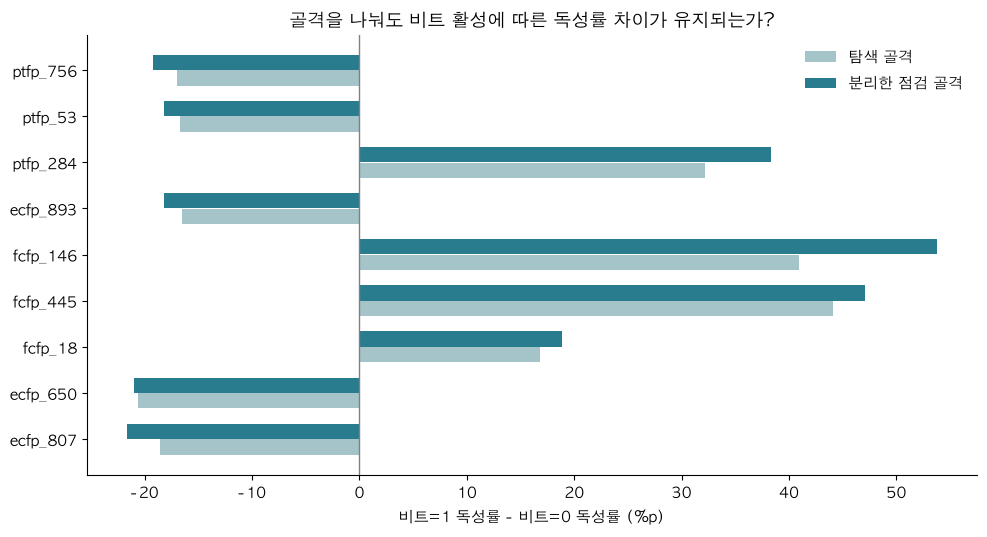

In [7]:
from sklearn.model_selection import GroupShuffleSplit

pre_splitter=GroupShuffleSplit(n_splits=1,test_size=.3,random_state=20261019)
pre_discovery_ids,pre_check_ids=next(pre_splitter.split(pre_unique,groups=pre_scaffolds))
assert not (set(pre_scaffolds[pre_discovery_ids])&set(pre_scaffolds[pre_check_ids]))
pre_split_rows=[]
for name,ids in [('탐색',pre_discovery_ids),('점검',pre_check_ids)]:
    pre_split_rows.append({'부분':name,'분자 수':len(ids),'골격 수':len(set(pre_scaffolds[ids])),
                           '독성 비율(%)':100*pre_toxic[ids].mean()})
display(pd.DataFrame(pre_split_rows).set_index('부분'))
print('전체 고유 골격 수:',len(set(pre_scaffolds)))

pre_unique_fp=pre_unique[pre_fps].to_numpy(dtype=np.uint8)
def pre_bit_table(values,outcome):
    present=values==1
    a=int((present&(outcome==1)).sum());b=int((present&(outcome==0)).sum())
    c=int((~present&(outcome==1)).sum());d=int((~present&(outcome==0)).sum())
    return a,b,c,d

pre_candidates=[]
for j,col in enumerate(pre_fps):
    a,b,c,d=pre_bit_table(pre_unique_fp[pre_discovery_ids,j],pre_toxic[pre_discovery_ids])
    if a+b<100 or c+d<100:continue
    pre_candidates.append({'비트':col,'묶음':col.split('_')[0],
       '탐색 p':stats.fisher_exact([[a,b],[c,d]]).pvalue,
       '탐색 차이(%p)':100*(a/(a+b)-c/(c+d))})
pre_candidate_table=pd.DataFrame(pre_candidates)
pre_selected=(pre_candidate_table.sort_values(['탐색 p','비트'])
              .groupby('묶음',sort=True).head(3)).copy()
pre_stability_rows=[]
for _,row in pre_selected.iterrows():
    j=pre_fps.index(row['비트'])
    a,b,c,d=pre_bit_table(pre_unique_fp[pre_check_ids,j],pre_toxic[pre_check_ids])
    if a+b==0 or c+d==0:continue
    diff=100*(a/(a+b)-c/(c+d))
    pre_stability_rows.append({'비트':row['비트'],'탐색 차이(%p)':row['탐색 차이(%p)'],
       '점검 차이(%p)':diff,'점검 활성 수':a+b,'점검 비활성 수':c+d,
       '점검 p':stats.fisher_exact([[a,b],[c,d]]).pvalue,
       '방향 일치':bool(np.sign(diff)==np.sign(row['탐색 차이(%p)']))})
pre_stability=pd.DataFrame(pre_stability_rows).set_index('비트')
pre_stability['점검 Holm p']=pre_holm(pre_stability['점검 p'])
pre_stability['보정 후 근거']=pre_stability['점검 Holm p']<.05
display(pre_stability[['탐색 차이(%p)','점검 차이(%p)','점검 활성 수','점검 비활성 수',
                       '방향 일치','보정 후 근거']].round(2))
fig,ax=plt.subplots(figsize=(10,5.5))
y=np.arange(len(pre_stability))
ax.barh(y-.17,pre_stability['탐색 차이(%p)'],height=.33,label='탐색 골격',color='#A4C4CA')
ax.barh(y+.17,pre_stability['점검 차이(%p)'],height=.33,label='분리한 점검 골격',color='#287C8E')
ax.axvline(0,color='gray',lw=1);ax.set_yticks(y,labels=pre_stability.index)
ax.set(title='골격을 나눠도 비트 활성에 따른 독성률 차이가 유지되는가?',
       xlabel='비트=1 독성률 - 비트=0 독성률 (%p)');ax.legend(frameon=False)
fig.tight_layout();plt.show()

**해석**: 고유 골격 **4,160개**를 탐색 5,843개 분자와 점검 2,505개 분자로 분리. 선택한 **비트 9개 모두**에서 독성률 차이의 방향이 유지되고, 점검 부분에서도 Holm 보정 기준을 통과.

**전처리 판단**: 이 비트들은 특정 골격에만 국한되지 않는 신호 후보. 다만 서로 겹치는 정보를 가질 수 있어 곧바로 9개만 남기는 근거는 아님.

**한계**: 이미 전체 자료를 살펴본 뒤의 탐색적 분리이므로 독립적인 확증 결과가 아님. 서로 다른 골격도 유사할 수 있으며 점검 부분의 Fisher 검정은 행 독립을 가정. 한 번의 분리만으로 일반화 성능을 주장하지 않음.

### 8-7. 파일 앞뒤가 비슷한 데이터인가?

**왜 확인하는가?** 파일이 분자량순으로 정렬되거나 여러 묶음으로 합쳐져 있다면, 앞 80%와 뒤 20%를 나누는 것만으로 서로 다른 구성이 될 수 있기 때문.

**방법**: 원래 CSV 행 순서와 분자량의 관계, 500행 단위 독성 비율 확인. 실제 출처나 시간 정보를 추정해 채우지는 않음.

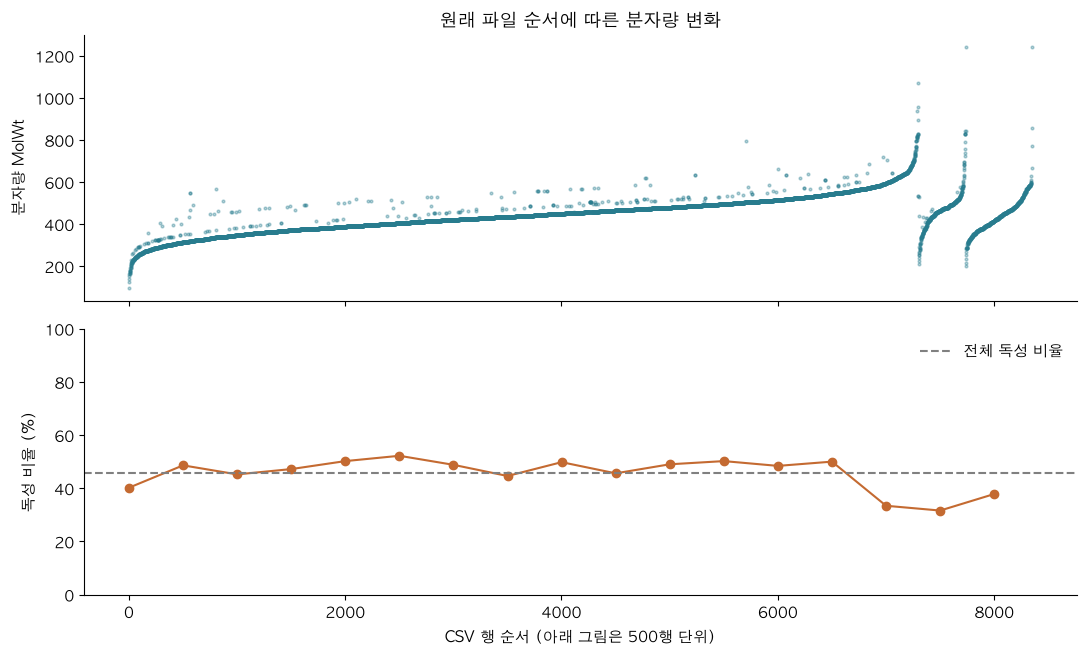

행 순서와 분자량의 순위 상관: 0.779
각 묶음의 표본 수: [500, 500, 500, 500, 500, 500, 500, 500, 500, 500, 500, 500, 500, 500, 500, 500, 349]


In [8]:
pre_row_order=np.arange(len(pre_raw))
pre_order_r=float(stats.spearmanr(pre_row_order,pre_raw.MolWt).statistic)
pre_order_source=pd.DataFrame({'block':pre_row_order//500,'toxic':pre_raw.label.eq(0).astype(int)})
pre_order_table=pre_order_source.groupby('block').toxic.agg(n='size',toxic_n='sum',rate='mean')
fig,axes=plt.subplots(2,1,figsize=(11,6.7),sharex=True)
axes[0].scatter(pre_row_order+2,pre_raw.MolWt,s=4,alpha=.35,color='#287C8E')
axes[0].set(title='원래 파일 순서에 따른 분자량 변화',ylabel='분자량 MolWt')
axes[1].plot(pre_order_table.index*500+2,pre_order_table.rate*100,'o-',color='#C46A31')
axes[1].axhline(pre_raw.label.eq(0).mean()*100,color='gray',ls='--',label='전체 독성 비율')
axes[1].set(xlabel='CSV 행 순서 (아래 그림은 500행 단위)',ylabel='독성 비율 (%)',ylim=(0,100))
axes[1].legend(frameon=False)
fig.tight_layout();plt.show()
print(f'행 순서와 분자량의 순위 상관: {pre_order_r:.3f}')
print('각 묶음의 표본 수:',pre_order_table.n.to_list())

**해석**: 행 순서와 분자량의 상관은 약 **0.779**. 무작위 순서로 가정하기 어려운 배열. 정렬이나 자료 결합의 흔적일 수 있으나 실제 배치나 원인은 확인 불가.

**처리 방향**: 앞뒤를 그대로 잘라 검증하는 방법은 피하고, 동일 분자를 묶은 층화 분리와 골격 분리의 목적을 구분. 실제 출처를 확보하면 출처별 점검 추가.

### 8-8. 전처리 판단 정리

| 확인 항목 | 현재 판단 | 다음 처리 |
| --- | --- | --- |
| 결측치 | 없음 | 대체 불필요 |
| 상수·중복 열 | 제거 후보 존재 | 학습 부분에서 목록 결정 후 일관되게 적용 |
| 동일 수치 입력·다른 정답 | 표현 손실 또는 측정·정답 차이 후보 | 원자료 확인 전 자동 삭제 보류 |
| 입체화학 | 입력 구분 가능성 개선 | 보존 표현 추가 후보로 비교, 성능 향상은 별도 검증 |
| 물성 중복 | 단독 비교와 조건부 결과가 다를 수 있음 | 단변량 p값만으로 열 삭제하지 않기 |
| 고유사도 정답 불일치 | 구조가 비슷해도 정답이 다를 수 있음 | 해당 분자와 실험 조건 검토 |
| 골격과 행 순서 | 분리 방식이 결과에 영향을 줄 가능성 | 무작위 그룹 분리와 골격 분리 결과 구분 |

원본 수정, 정답 교체, 충돌 행 자동 삭제 및 예측 모델 성능 평가 미수행.

참고 자료: 사용자 제공 `EDA_report.html`. 방법 참고: [RDKit FingerprintGenerator](https://www.rdkit.org/docs/source/rdkit.Chem.rdFingerprintGenerator.html), [Murcko 골격](https://www.rdkit.org/docs/source/rdkit.Chem.Scaffolds.MurckoScaffold.html).

## 9. 분석 검토와 보완: 다음 실험을 시작해도 되는가?

**판정: 한계를 명시하면 모델 실험을 설계하기에 충분.** 기존 EDA의 분포, 효과크기, 다중검정 보정과 입력 손실 점검을 유지하고, 같은 골격의 분자들이 비슷할 가능성과 분할에 따른 변동을 추가 확인.

원자료 수정 없음. 아래 코드는 `analysis/eda_review.py`를 실행하여 현재 CSV에서 결과를 다시 계산. 모델 성능이나 독립 확증 분석과 구분.

In [1]:
from pathlib import Path
import runpy,contextlib,io
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import font_manager

font_path=Path('/System/Library/Fonts/Supplemental/AppleGothic.ttf')
if font_path.is_file():
    font_manager.fontManager.addfont(str(font_path))
    plt.rcParams['font.family']=font_manager.FontProperties(fname=str(font_path)).get_name()
else:
    fonts=[f for f in ['NanumGothic','Nanum Gothic','Malgun Gothic','AppleGothic']
           if f in font_manager.get_font_names()]
    if not fonts:raise RuntimeError('한글 글꼴 설치 후 커널 재시작 필요')
    plt.rcParams['font.family']=fonts[0]
plt.rcParams['axes.unicode_minus']=False
with contextlib.redirect_stdout(io.StringIO()):
    review=runpy.run_path('analysis/eda_review.py')['run']()
print(f'고유 분자 {review["unique_n"]:,}개 / 중심 골격 {review["scaffold_n"]:,}개')
print('입력 SHA-256:',review['source_sha256'])

고유 분자 8,348개 / 중심 골격 4,160개
입력 SHA-256: cb7118a9533e36d81cdb4aa2e9318e9fa0b80faa70d132d7d3b2009e81fca5d8


### 9-1. 골격끼리 묶어도 clogp 차이가 유지되는가?

**왜 확인했는가?** 비슷한 분자를 모두 독립이라고 보면 불확실성을 작게 평가할 수 있기 때문.

**방법**: 같은 골격의 분자들을 한 묶음으로 2,000회 다시 뽑고, clogp 최고·최저 5분위의 독성률 차이 계산. 분위 경계는 고정.

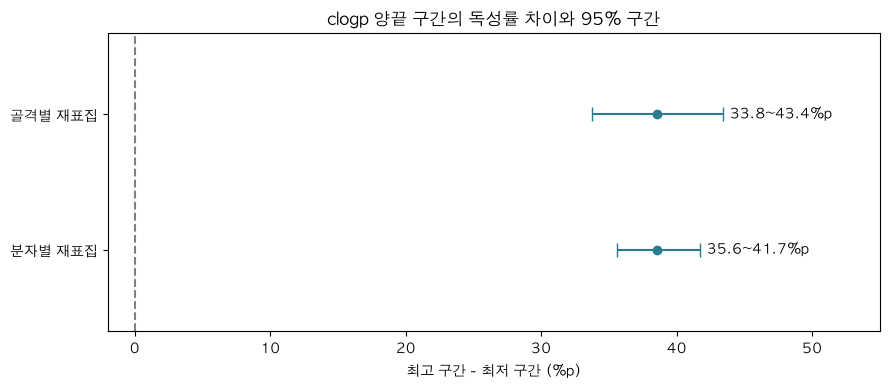

,method,difference_pp,low_pp,high_pp,replicates
0,분자별 재표집,38.563,35.569,41.738,2000
1,골격별 재표집,38.563,33.764,43.439,2000


In [2]:
intervals=pd.DataFrame(review['bootstrap'])
fig,ax=plt.subplots(figsize=(9,4))
for i,row in intervals.iterrows():
    ax.errorbar(row.difference_pp,i,xerr=[[row.difference_pp-row.low_pp],
                                        [row.high_pp-row.difference_pp]],fmt='o',capsize=5,color='#287C8E')
    ax.text(row.high_pp+.5,i,f'{row.low_pp:.1f}~{row.high_pp:.1f}%p',va='center')
ax.axvline(0,color='gray',linestyle='--');ax.set_yticks(range(2),labels=intervals.method)
ax.set(title='clogp 양끝 구간의 독성률 차이와 95% 구간',xlabel='최고 구간 - 최저 구간 (%p)',
       xlim=(-2,55),ylim=(-.6,1.6))
fig.tight_layout();plt.show()
display(intervals.round(3))

**결과**: 차이 **38.6%p**. 분자별 재표집 구간 **35.6~41.7%p**, 골격별 구간 **33.8~43.4%p**. 골격 의존성을 고려하면 구간이 넓어지지만 높은 clogp 쪽의 독성이 더 많은 방향 유지.

골격 사이도 유사할 수 있고 수집 편향은 반영되지 않음. 이것만으로 인과효과나 새 분자의 독성을 판정할 수 없음.

### 9-2. 골격 분할을 바꿔도 구조 비트의 방향이 유지되는가?

**방법**: 8절의 탐색 부분에서 선택한 비트 9개를 고정. 골격이 양쪽에 겹치지 않는 70:30 분할을 난수값 20261020~20261039로 20번 변경. 각 점검 부분에서 비트=1과 0의 독성률 차이 확인. 새로운 p값 선정은 미수행.

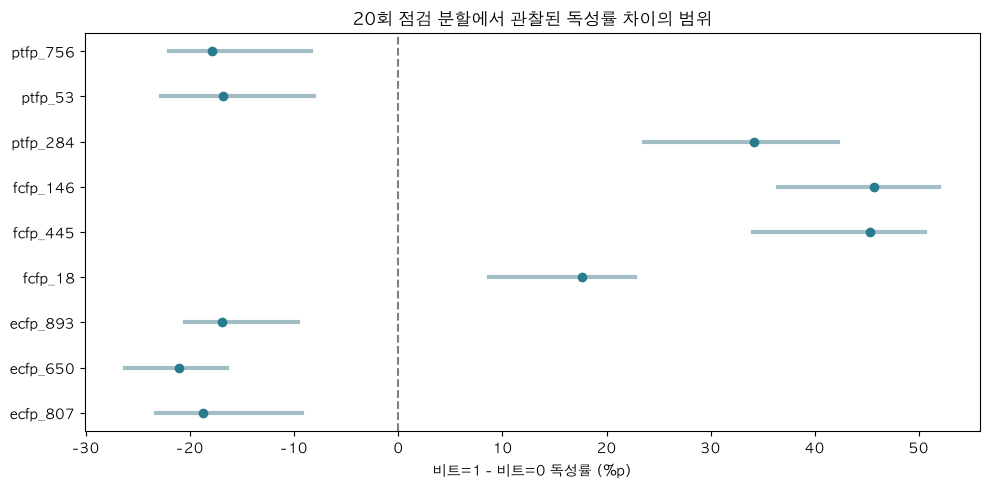

,bit,direction_consistency_percent,min_active,min_inactive
0,ecfp_807,100.0,1438,806
1,ecfp_650,100.0,1723,515
2,ecfp_893,100.0,1271,986
3,fcfp_18,100.0,1015,1093
4,fcfp_445,100.0,42,2221
5,fcfp_146,100.0,60,2179
6,ptfp_284,100.0,102,2133
7,ptfp_53,100.0,1614,638
8,ptfp_756,100.0,1685,566


In [3]:
repeat_table=pd.DataFrame(review['split_stability'])
fig,ax=plt.subplots(figsize=(10,5))
for i,row in repeat_table.iterrows():
    ax.plot([row.min_difference_pp,row.max_difference_pp],[i,i],color='#A1BEC4',lw=3)
    ax.plot(row.median_difference_pp,i,'o',color='#287C8E')
ax.axvline(0,color='gray',linestyle='--');ax.set_yticks(range(len(repeat_table)),labels=repeat_table.bit)
ax.set(title='20회 점검 분할에서 관찰된 독성률 차이의 범위',xlabel='비트=1 - 비트=0 독성률 (%p)')
fig.tight_layout();plt.show()
display(repeat_table[['bit','direction_consistency_percent','min_active','min_inactive']])

**결과**: 9개 비트 모두 **20/20회 같은 방향**. 일부 활성 표본은 최소 42개에 불과해 효과의 크기는 분할마다 달라짐. 선은 20회에서 관찰한 최솟값~최댓값이며 신뢰구간과 구분.

전체 자료에서 이미 관찰한 후보를 겹치는 분할로 재확인한 결과이므로 독립 검증 20회가 아님. 9개가 최적의 입력이라는 결론도 아님.

### 9-3. 파일 앞뒤의 조성 변화가 clogp 경향을 설명하는가?

**방법**: 원래 행 순서를 4구간으로 나누고 각 구간에서 같은 clogp 양끝 범위의 독성률 비교. 실제 수집 배치나 시간으로 해석하지 않음.

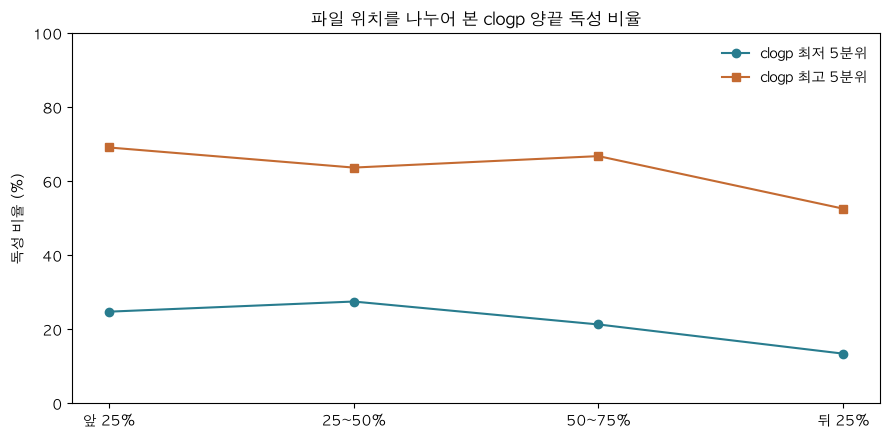

,quarter,low_n,high_n,low_rate_percent,high_rate_percent,difference_pp
0,앞 25%,557,149,24.78,69.13,44.35
1,25~50%,378,303,27.51,63.70,36.18
2,50~75%,333,524,21.32,66.79,45.47
3,뒤 25%,402,694,13.43,52.59,39.16


In [4]:
quarters=pd.DataFrame(review['row_quarters'])
x=np.arange(len(quarters))
fig,ax=plt.subplots(figsize=(9,4.5))
ax.plot(x,quarters.low_rate_percent,'o-',label='clogp 최저 5분위',color='#287C8E')
ax.plot(x,quarters.high_rate_percent,'s-',label='clogp 최고 5분위',color='#C46A31')
ax.set_xticks(x,labels=quarters.quarter)
ax.set(title='파일 위치를 나누어 본 clogp 양끝 독성 비율',ylabel='독성 비율 (%)',ylim=(0,100))
ax.legend(frameon=False);fig.tight_layout();plt.show()
display(quarters.round(2))

**결과**: 파일 4구간 모두 최고 clogp 쪽의 독성률이 높았고, 차이는 **36.2~45.5%p**. 순서에 따른 조성 변화만으로 전체 관계가 생겼다고 볼 근거는 약해짐. 다만 실제 출처·실험 조건의 영향은 미확인.

### 검토 결론

기존 EDA의 주요 방향은 유지 가능. 다음은 **같은 평가 분할에서 기존 입력과 입체화학을 보존한 입력의 예측 성능 비교**. 상수·중복 열 제거는 학습 부분에서 결정하고, 같은 연결 구조의 분자가 학습과 평가 양쪽에 나뉘지 않도록 그룹 설정. 과제 F1(비독성=1)과 독성 Recall(0)을 함께 확인.

예측용 CSV, 독성 endpoint, 농도 및 실험 조건은 미제공이므로 입력 분포 이동과 사람의 안전성은 판단 불가. 이번 절에서도 예측 모델을 학습하거나 F1을 측정하지 않음.

## 10. RDKit 분자 특성으로 모델 입력 확장

**목적:** 기존 SMILES에서 극성, 수소결합, 고리, 유연성 등의 정보를 계산해 모델 입력에 추가.
외부 데이터 수집이나 분자 수 증가가 아니라 **같은 분자에 대한 컬럼 확장**.

원본 CSV와 기존 EDA는 유지. 기존 수치 입력 전체에 30개 RDKit 특성을 추가하며, 기존 MolWt와 clogp를 그대로 다시 계산하는 항목은 제외.
`X_base`, `X_expanded`, `y_model`, `model_smiles`를 생성한다. 원본 행 순서와 label(0=독성, 1=비독성) 유지.

추가 패키지 설치 없이 기존 `pandas`, `numpy`, `rdkit` 사용. 이 절은 앞 절을 실행하지 않아도 프로젝트 루트에서 실행 가능.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
from IPython.display import display
from rdkit import Chem, rdBase
from rdkit.Chem import Descriptors

# 버전과 데이터 출처를 기록하고 원본을 새로 읽는다.
feature_source = Path('Data/input_data/train.csv')
feature_data = pd.read_csv(feature_source)
rdkit_descriptor_names = [
    'TPSA', 'LabuteASA', 'MolMR', 'ExactMolWt',
    'NumHDonors', 'NumHAcceptors', 'NumHeteroatoms',
    'NumRotatableBonds', 'NHOHCount', 'NOCount',
    'RingCount', 'NumAromaticRings', 'NumAliphaticRings',
    'NumSaturatedRings', 'NumAromaticHeterocycles',
    'NumAromaticCarbocycles', 'NumAliphaticHeterocycles',
    'NumAliphaticCarbocycles', 'FractionCSP3',
    'HeavyAtomCount', 'NumValenceElectrons', 'NumRadicalElectrons',
    'NumBridgeheadAtoms', 'NumSpiroAtoms', 'BertzCT',
    'BalabanJ', 'HallKierAlpha', 'Kappa1', 'Kappa2', 'Kappa3',
]
# API 이름을 먼저 확인해 함수 오류로 전체 열이 실패하는 상황을 방지.
rdkit_functions = {name: getattr(Descriptors, name) for name in rdkit_descriptor_names}

def make_rdkit_features(smiles):
    """행을 유지하고 실패값은 NaN, 실패 이유는 별도 표로 반환."""
    records, failures = [], []
    for row_index, value in smiles.items():
        mol = Chem.MolFromSmiles(value) if isinstance(value, str) else None
        record = {}
        for name, function in rdkit_functions.items():
            column = 'rdkit_' + name
            try:
                if mol is None:
                    raise ValueError('SMILES parsing failed')
                result = float(function(mol))
                if not np.isfinite(result):
                    raise ValueError('non-finite descriptor')
                record[column] = result
            except Exception as exc:
                record[column] = np.nan
                failures.append({'row_index': row_index, 'feature': column,
                                 'reason': str(exc)})
        records.append(record)
    return (pd.DataFrame(records, index=smiles.index,
                         columns=['rdkit_' + name for name in rdkit_functions]),
            pd.DataFrame(failures, columns=['row_index', 'feature', 'reason']))

rdkit_features, rdkit_failures = make_rdkit_features(feature_data['SMILES'])
print(f'RDKit {rdBase.rdkitVersion} / 원본 {len(feature_data):,}행')
print(f'추가 특성 {rdkit_features.shape[1]}개 / 실패 셀 {len(rdkit_failures):,}개')
display(rdkit_features.iloc[:3, :8].round(3))

RDKit 2026.09.1 / 원본 8,349행
추가 특성 30개 / 실패 셀 0개


,rdkit_TPSA,rdkit_LabuteASA,rdkit_MolMR,rdkit_ExactMolWt,rdkit_NumHDonors,rdkit_NumHAcceptors,rdkit_NumHeteroatoms,rdkit_NumRotatableBonds
0,38.91,41.991,28.649,94.053,1.0,2.0,2.0,0.0
1,65.98,51.514,30.284,126.043,2.0,2.0,4.0,1.0
2,80.39,48.438,30.087,139.030,2.0,3.0,5.0,3.0


### 10-1. 생성 품질과 기존 정보의 중복 확인

생성 실패, 상수 열, 기존 물성 및 새 특성 사이의 **값이 완전히 같은 열**을 확인. 이 표는 진단용이며 여기서 자동 삭제하거나 결측을 채우지 않음.
ExactMolWt 등은 기존 MolWt와 강하게 연관될 수 있으므로, 새 컬럼 수가 독립적인 정보 수를 뜻하지 않음.
학습 때 결측 대체, 상수·중복 제거, 피처 선택은 **각 학습 Fold에서만 결정**하고 검증·예측 자료에 동일 적용.

In [2]:
rdkit_quality = pd.DataFrame({
    '결측 수': rdkit_features.isna().sum(),
    '고유값 수': rdkit_features.nunique(),
    '최솟값': rdkit_features.min(),
    '중앙값': rdkit_features.median(),
    '최댓값': rdkit_features.max(),
})
rdkit_quality['상수 후보'] = rdkit_quality['고유값 수'].le(1)
original_properties = ['MolWt', 'clogp', 'sa_score', 'qed']
comparison_features = pd.concat([feature_data[original_properties], rdkit_features], axis=1)
exact_duplicate_pairs = []
for position, column in enumerate(comparison_features.columns):
    for previous in comparison_features.columns[:position]:
        if np.array_equal(comparison_features[column].to_numpy(),
                          comparison_features[previous].to_numpy(), equal_nan=True):
            exact_duplicate_pairs.append((previous, column))
display(rdkit_quality.round(3))
print('완전히 같은 값의 물성 열 쌍:', exact_duplicate_pairs)
if not rdkit_failures.empty:
    display(rdkit_failures.head(10))

,결측 수,고유값 수,최솟값,중앙값,최댓값,상수 후보
rdkit_TPSA,0,3101,0.000,77.050,496.680,False
rdkit_LabuteASA,0,7213,41.991,185.498,513.210,False
rdkit_MolMR,0,7261,28.649,118.604,341.591,False
rdkit_ExactMolWt,0,6395,94.053,441.185,1241.713,False
rdkit_NumHDonors,0,10,0.000,1.000,18.000,False
rdkit_NumHAcceptors,0,18,0.000,5.000,17.000,False
rdkit_NumHeteroatoms,0,23,0.000,8.000,30.000,False
rdkit_NumRotatableBonds,0,20,0.000,6.000,32.000,False
rdkit_NHOHCount,0,11,0.000,1.000,18.000,False
rdkit_NOCount,0,20,0.000,7.000,30.000,False


완전히 같은 값의 물성 열 쌍: []


### 10-2. 확장된 모델 입력 준비

SMILES와 정답은 숫자 입력에서 분리. SMILES는 이후 분자·골격 그룹 생성에 사용.
입력에 원래 label이나 분석용 toxic 변수가 들어가지 않도록 원본 CSV에서 명시적으로 컬럼 선택.
`X_expanded`에는 결측 대체나 스케일링을 미리 적용하지 않는다.
예측 CSV가 추가되면 같은 함수, 같은 컬럼 순서로 변환하며 결측 대체값은 학습 자료에서 가져와야 한다.

In [3]:
base_feature_columns = [
    column for column in feature_data.columns
    if column.startswith(('ecfp_', 'fcfp_', 'ptfp_'))
] + original_properties
X_base = feature_data[base_feature_columns].copy()
X_expanded = pd.concat([X_base, rdkit_features], axis=1)
y_model = feature_data['label'].astype(int).copy()
model_smiles = feature_data['SMILES'].copy()
assert X_expanded.index.equals(y_model.index)
assert X_expanded.columns.is_unique
assert not {'label', 'toxic', 'SMILES'} & set(X_expanded.columns)
assert X_expanded.shape[1] == X_base.shape[1] + len(rdkit_descriptor_names)
assert y_model.isin([0, 1]).all()
print(f'기존 입력: {X_base.shape} → 확장 입력: {X_expanded.shape}')
print(f'정답: {y_model.shape}, 0=독성 있음, 1=독성 없음')
print('변수: X_base / X_expanded / y_model / model_smiles')

# 생성된 특성만 별도 저장. 행 순서와 연결 키를 함께 보존한다.
feature_output = Path('Data/processed_data')
feature_output.mkdir(parents=True, exist_ok=True)
rdkit_export = rdkit_features.copy()
rdkit_export.insert(0, 'SMILES', model_smiles)
rdkit_export.insert(0, 'source_row', np.arange(len(feature_data)))
rdkit_export.to_csv(feature_output / 'train_rdkit_features.csv', index=False)
print('저장:', feature_output / 'train_rdkit_features.csv')

기존 입력: (8349, 3076) → 확장 입력: (8349, 3106)
정답: (8349,), 0=독성 있음, 1=독성 없음
변수: X_base / X_expanded / y_model / model_smiles
저장: Data/processed_data/train_rdkit_features.csv


### 다음 실험 순서

1. 같은 그룹 분할에서 `X_base`로 LightGBM 기준 성능 측정.
2. 같은 모델·설정으로 `X_expanded` 평가해 RDKit 추가 효과만 비교.
3. 별도로 입체화학 Fingerprint 추가, 이후 RDKit과 함께 추가한 경우 비교.
4. F1(비독성=1), 독성 Recall(0), 학습 시간과 Fold별 변동 함께 기록.

**현재 단계는 입력 생성 완료이며, 성능 향상을 확인한 단계는 아님.**
방법: [RDKit Descriptors](https://www.rdkit.org/docs/source/rdkit.Chem.Descriptors.html).

## 11. hERG 도메인 가설에 따른 피처 후보 선택

**판정:** 공개 hERG 자료와 분자 구조·라벨의 높은 일치율은 hERG 관련 데이터라는 강한 근거. 원본 가공 경로와 실험 판정 기준까지 확정한 것은 아님.
로컬 label은 그대로 0=독성, 1=비독성 유지. hERG 가설에서는 차단/비차단에 대응할 가능성이 높으며, 사람의 부정맥 발생 여부와 구분.

출처 점검은 `analysis/herg_source_check.py`, 계산 근거는 `analysis/herg_source_evidence.json`.
외부 라벨은 출처 대조에만 사용하고 모델 입력·라벨 수정·피처 성능 선별에는 사용하지 않음.

### 선택 근거

| 정보 | 후보 | hERG 관점 |
| --- | --- | --- |
| 지용성 | clogp | 소수성 결합 관련 후보 |
| 크기와 분극성 | MolWt, MolMR, LabuteASA | 결합 부위와의 크기·상호작용 후보 |
| 극성·수소결합 | TPSA, HBD, HBA | 지용성과 함께 비교할 물성 |
| 방향족·고리 | 방향족 고리, 전체 고리, 방향족·지방족 헤테로고리 | 구조와 방향족 상호작용 후보 |
| 유연성·포화도 | 회전 결합, FractionCSP3 | 가능한 구조 배치 관련 후보 |
| 전하·이온화 구조 | 형식전하, 양·음전하 원자, PosIonizable·NegIonizable 패턴 | 양성자화 가능한 중심의 대리 정보 |

**pKa, pH 7.4에서의 logD·이온화 비율은 RDKit 기본 계산으로 얻었다고 간주하지 않음.**
형식전하는 입력 SMILES에 적힌 전하이고, 이온화 패턴 수는 RDKit 규칙의 구조 후보 수. 실제 pKa나 생리 pH 전하를 뜻하지 않음.
참고: [지용성 연구](https://pubmed.ncbi.nlm.nih.gov/17239590/), [이온화 유형 연구](https://pubmed.ncbi.nlm.nih.gov/27783199/), [hERG 구조·유연성 연구](https://pmc.ncbi.nlm.nih.gov/articles/PMC6704061/).

다음 코드는 10절의 입력 생성 후 실행. **문헌 기반 후보 선택이며 검증 성능으로 확정한 최종 선택은 아님.**

In [4]:
import json
from pathlib import Path
from rdkit import RDConfig
from rdkit.Chem import ChemicalFeatures

# 외부 자료는 출처 대조 결과만 읽음. 모델 입력에 합치지 않음.
herg_evidence_path = Path('analysis/herg_source_evidence.json')
if herg_evidence_path.exists():
    herg_evidence = json.loads(herg_evidence_path.read_text())
    display(pd.DataFrame([
        {'공개 자료': name, '공개 행 수': values['public_rows'],
         '일치한 로컬 행 수': values['matched_local_rows']}
        for name, values in herg_evidence['sources'].items()
    ]))

herg_selected_columns = [
    'clogp', 'MolWt', 'rdkit_MolMR', 'rdkit_LabuteASA',
    'rdkit_TPSA', 'rdkit_NumHDonors', 'rdkit_NumHAcceptors',
    'rdkit_NumAromaticRings', 'rdkit_RingCount',
    'rdkit_NumAromaticHeterocycles', 'rdkit_NumAliphaticHeterocycles',
    'rdkit_NumRotatableBonds', 'rdkit_FractionCSP3',
]
herg_factory = ChemicalFeatures.BuildFeatureFactory(
    str(Path(RDConfig.RDDataDir) / 'BaseFeatures.fdef'))

def make_herg_structure_proxies(smiles):
    records = []
    for value in smiles:
        mol = Chem.MolFromSmiles(value)
        if mol is None:
            raise ValueError('hERG 구조 후보 생성 전 SMILES 파싱 오류 확인 필요')
        charges = [atom.GetFormalCharge() for atom in mol.GetAtoms()]
        families = [feature.GetFamily() for feature in herg_factory.GetFeaturesForMol(mol)]
        records.append({
            'herg_FormalCharge': sum(charges),
            'herg_AbsFormalCharge': sum(abs(charge) for charge in charges),
            'herg_PositiveAtomCount': sum(charge > 0 for charge in charges),
            'herg_NegativeAtomCount': sum(charge < 0 for charge in charges),
            'herg_PosIonizablePatternCount': families.count('PosIonizable'),
            'herg_NegIonizablePatternCount': families.count('NegIonizable'),
        })
    return pd.DataFrame(records, index=smiles.index)

herg_structure_proxies = make_herg_structure_proxies(model_smiles)
X_herg_domain = pd.concat([
    X_expanded[herg_selected_columns], herg_structure_proxies
], axis=1)
# 구조 비트는 별도 정보이므로 도메인 물성 후보만 보고 자동 제거하지 않는다.
herg_fp_columns = [column for column in X_base
                   if column.startswith(('ecfp_', 'fcfp_', 'ptfp_'))]
X_herg_expanded = pd.concat([X_base[herg_fp_columns], X_herg_domain], axis=1)
assert X_herg_expanded.index.equals(y_model.index)
assert X_herg_expanded.columns.is_unique
assert not {'label', 'toxic', 'ACTIVITY', 'PIC50', 'SMILES'} & set(X_herg_expanded.columns)
assert np.isfinite(X_herg_domain.to_numpy()).all()
print(f'도메인 물성·구조 후보: {X_herg_domain.shape}')
print(f'Fingerprint + 도메인 후보: {X_herg_expanded.shape}')
display(herg_structure_proxies.agg(['min', 'median', 'max']).T)


,공개 자료,공개 행 수,일치한 로컬 행 수
0,cardiotox,12620,6954
1,toxtree,8879,5590


도메인 물성·구조 후보: (8349, 19)
Fingerprint + 도메인 후보: (8349, 3091)


,min,median,max
herg_FormalCharge,0.0,0.0,1.0
herg_AbsFormalCharge,0.0,0.0,4.0
herg_PositiveAtomCount,0.0,0.0,2.0
herg_NegativeAtomCount,0.0,0.0,2.0
herg_PosIonizablePatternCount,0.0,1.0,8.0
herg_NegIonizablePatternCount,0.0,0.0,4.0


### 11-1. 후보 목록 보존과 비교 설계

`X_herg_domain`은 선택한 물성·구조 정보만, `X_herg_expanded`는 기존 Fingerprint와 해당 후보를 결합한 입력.
`qed`, `sa_score` 등은 원래 입력과 10절의 `X_expanded`에 보존. hERG 후보에 없다는 이유로 무용하다고 판단하지 않음.
상수·중복 제거와 학습 기반 피처 선택은 학습 Fold 안에서만 수행.

1. 동일한 분할에서 기존 입력, 10절의 확장 입력, hERG 도메인 후보 입력 비교.
2. 지용성, 극성, 방향족, 전하·이온화 구조 묶음을 하나씩 제외해 추가 기여 확인.
3. 입체화학 Fingerprint를 별도 비교. 도메인 물성은 입체화학 정보를 대체하지 않음.
4. F1(비독성=1), 독성 Recall(0), Fold별 변동 확인. 새 골격 성능은 골격 분할로 별도 평가.

공개 데이터와 맞지 않는 라벨은 자동 수정하지 않음. 외부 자료를 합칠 경우 분자 중복과 라벨 출처 누출을 먼저 점검.


In [5]:
herg_manifest = {
    'selection_type': 'literature-informed candidate set; not performance-selected',
    'endpoint_status': 'strong hERG evidence; exact local lineage and assay threshold unverified',
    'label_mapping_local': {'0': '독성 있음', '1': '독성 없음'},
    'domain_features': X_herg_domain.columns.tolist(),
    'fingerprint_features': herg_fp_columns,
    'excluded_from_domain_only': ['sa_score', 'qed', 'other RDKit descriptors'],
    'external_labels_used_as_features': False,
    'limitations': ['ionizable patterns are not pKa', 'formal charge is not charge at physiological pH',
                    'predictive improvement not evaluated'],
}
Path('analysis/herg_feature_manifest.json').write_text(
    json.dumps(herg_manifest, ensure_ascii=False, indent=2))
herg_export = herg_structure_proxies.copy()
herg_export.insert(0, 'SMILES', model_smiles)
herg_export.insert(0, 'source_row', np.arange(len(model_smiles)))
herg_export.to_csv('Data/processed_data/train_herg_structure_proxies.csv', index=False)
print('후보 목록: analysis/herg_feature_manifest.json')
print('추가 구조 피처: Data/processed_data/train_herg_structure_proxies.csv')

후보 목록: analysis/herg_feature_manifest.json
추가 구조 피처: Data/processed_data/train_herg_structure_proxies.csv


## 12. 참고 저장소 특성 통합과 학습 부분에서 피처 선택

기존 30개 RDKit 특성과 hERG 구조 후보에 참고 저장소 v6의 추가 특성을 통합.
참고의 48개 중 `BertzCT_Graph`는 `BertzCT`와 같은 계산이므로 한 번만 생성.
참고 코드의 `NumHeteroAtoms` 호출은 올바른 `NumHeteroatoms`로 수정.
기존 30개와 같은 이름인 특성도 한 번만 계산. 원본 전체 Fingerprint는 후보에 유지하고 참고의 Top 300 목록은 가져오지 않음.

[참고 v6](https://github.com/YunCheol07/DataAnalysisProject/blob/main/데이터분석_미니_프로젝트_정리_v6.ipynb)

**선택 순서:** 분자 그룹 분리 → 학습 부분만으로 결측·상수·중복 열 정리 → 학습 중앙값 대체 → ExtraTrees 중요도 상위 300개 선택 → 검증 부분에 동일 변환.
300은 최초 비교용 설정이며 최적 개수가 아님. 여기서는 최종 예측 모델을 학습하거나 검증 성능을 평가하지 않음.
이 절은 10절과 11절 실행 후 사용. 기존 `X_expanded`, `X_herg_expanded`는 그대로 보존.

In [6]:
reference_descriptor_names = ['NumHDonors', 'NumHAcceptors', 'NumHeteroatoms', 'NumRotatableBonds', 'NHOHCount', 'NOCount', 'RingCount', 'TPSA', 'LabuteASA', 'NumAromaticRings', 'NumAliphaticRings', 'NumSaturatedRings', 'NumAromaticHeterocycles', 'NumAromaticCarbocycles', 'NumAliphaticHeterocycles', 'NumAliphaticCarbocycles', 'BertzCT', 'Ipc', 'HallKierAlpha', 'Chi0v', 'Chi1v', 'Chi2v', 'Chi3v', 'Chi4v', 'Kappa1', 'Kappa2', 'Kappa3', 'PEOE_VSA1', 'PEOE_VSA2', 'PEOE_VSA3', 'SMR_VSA1', 'SMR_VSA2', 'SlogP_VSA1', 'SlogP_VSA2', 'MaxPartialCharge', 'MinPartialCharge', 'MaxAbsPartialCharge', 'NumBridgeheadAtoms', 'NumSpiroAtoms', 'HeavyAtomCount', 'NumValenceElectrons', 'NumRadicalElectrons', 'BalabanJ', 'MolMR', 'ExactMolWt', 'NumSaturatedHeterocycles', 'NumSaturatedCarbocycles']
combined_descriptor_names = list(dict.fromkeys(rdkit_descriptor_names + reference_descriptor_names))
# 기존 생성 함수를 재사용하되 통합한 함수 목록으로 계산한다.
previous_rdkit_functions = rdkit_functions
try:
    rdkit_functions = {name: getattr(Descriptors, name) for name in combined_descriptor_names}
    rdkit_combined, rdkit_combined_failures = make_rdkit_features(model_smiles)
finally:
    rdkit_functions = previous_rdkit_functions
X_candidates = pd.concat([X_base, rdkit_combined, herg_structure_proxies], axis=1)
assert X_candidates.columns.is_unique
assert X_candidates.index.equals(y_model.index)
assert not {'label', 'toxic', 'ACTIVITY', 'PIC50', 'SMILES'} & set(X_candidates.columns)
print(f'고유 RDKit 특성: {len(combined_descriptor_names)}개')
print(f'기존 입력 {X_base.shape[1]} + RDKit {rdkit_combined.shape[1]} + hERG 구조 {herg_structure_proxies.shape[1]} = 후보 {X_candidates.shape[1]}개')
print(f'생성 실패 셀: {len(rdkit_combined_failures)}')
if not rdkit_combined_failures.empty:
    display(rdkit_combined_failures.head(10))


고유 RDKit 특성: 48개
기존 입력 3076 + RDKit 48 + hERG 구조 6 = 후보 3130개
생성 실패 셀: 0


In [7]:
import hashlib
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.pipeline import Pipeline
from sklearn.ensemble import ExtraTreesClassifier
from sklearn.feature_selection import SelectFromModel
from sklearn.model_selection import StratifiedGroupKFold

class TrainOnlyFeatureCleaner(TransformerMixin, BaseEstimator):
    """학습 부분에서만 열 제거 목록과 중앙값을 결정한다."""
    def fit(self, X, y=None):
        frame = X.replace([np.inf, -np.inf], np.nan)
        self.feature_names_in_ = np.asarray(frame.columns, dtype=object)
        self.empty_columns_ = frame.columns[frame.isna().all()].tolist()
        self.constant_columns_ = frame.columns[
            frame.nunique(dropna=True).le(1) & ~frame.isna().all()].tolist()
        eligible = frame.drop(columns=self.empty_columns_ + self.constant_columns_)
        seen, duplicate_columns = {}, []
        for column in eligible:
            values = eligible[column].to_numpy(dtype=np.float64, copy=True)
            values[values == 0] = 0.0
            values[np.isnan(values)] = np.nan
            key = hashlib.sha256(values.tobytes()).digest()
            if key in seen:
                duplicate_columns.append(column)
            else:
                seen[key] = column
        self.duplicate_columns_ = duplicate_columns
        self.columns_ = eligible.drop(columns=duplicate_columns).columns.tolist()
        self.medians_ = frame[self.columns_].median()
        return self
    def transform(self, X):
        return (X[self.columns_].replace([np.inf, -np.inf], np.nan)
                .fillna(self.medians_).to_numpy(dtype=np.float64))
    def get_feature_names_out(self, input_features=None):
        return np.asarray(self.columns_, dtype=object)

# 입체화학 표기가 달라도 같은 연결 구조는 같은 그룹으로 유지.
selection_groups = model_smiles.map(
    lambda value: Chem.MolToSmiles(Chem.MolFromSmiles(value), isomericSmiles=False))
selection_split = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)
selection_train_ids, selection_valid_ids = next(
    selection_split.split(X_candidates, y_model, groups=selection_groups))
assert not (set(selection_groups.iloc[selection_train_ids]) &
            set(selection_groups.iloc[selection_valid_ids]))
feature_selection_pipeline = Pipeline([
    ('clean', TrainOnlyFeatureCleaner()),
    ('select', SelectFromModel(
        ExtraTreesClassifier(n_estimators=128, max_features='sqrt',
                             class_weight='balanced', random_state=42, n_jobs=-1),
        threshold=-np.inf, max_features=300)),
])
# 검증 label은 fit, 중요도 계산, 피처 개수 선택에 사용하지 않음.
X_selection_train = feature_selection_pipeline.fit_transform(
    X_candidates.iloc[selection_train_ids], y_model.iloc[selection_train_ids])
X_selection_valid = feature_selection_pipeline.transform(X_candidates.iloc[selection_valid_ids])
cleaner = feature_selection_pipeline.named_steps['clean']
selector = feature_selection_pipeline.named_steps['select']
cleaned_names = cleaner.get_feature_names_out()
selected_feature_names = cleaned_names[selector.get_support()].tolist()
feature_selection_table = pd.DataFrame({
    'feature': cleaned_names,
    'importance': selector.estimator_.feature_importances_,
    'selected': selector.get_support(),
}).sort_values('importance', ascending=False)
print(f'후보 {X_candidates.shape[1]} → 학습 부분 정리 후 {len(cleaned_names)} → 선택 {len(selected_feature_names)}')
print(f'학습 변환: {X_selection_train.shape}, 검증 변환: {X_selection_valid.shape}')
print(f'제거: 전체 결측 {len(cleaner.empty_columns_)}, 상수 {len(cleaner.constant_columns_)}, 중복 {len(cleaner.duplicate_columns_)}')
display(feature_selection_table.head(20).round(5))
feature_selection_table.to_csv('Data/processed_data/feature_selection_importance.csv', index=False)
Path('Data/processed_data/selected_feature_names.json').write_text(
    json.dumps(selected_feature_names, ensure_ascii=False, indent=2))


후보 3130 → 학습 부분 정리 후 3019 → 선택 300
학습 변환: (6679, 300), 검증 변환: (1670, 300)
제거: 전체 결측 0, 상수 51, 중복 60


,feature,importance,selected
2963,clogp,0.00459,True
1949,fcfp_926,0.00404,True
1042,fcfp_18,0.00398,True
2966,rdkit_TPSA,0.00348,True
807,ecfp_807,0.00320,True
219,ecfp_219,0.00317,True
893,ecfp_893,0.00310,True
2964,sa_score,0.00279,True
650,ecfp_650,0.00279,True
2981,rdkit_NumAromaticCarbocycles,0.00275,True


4594

### 해석과 다음 비교

위 목록은 한 학습 분할의 모델 중요도로 고른 **탐색적 후보 300개**. 도메인 후보가 전부 살아남아야 하는 것은 아니며, 중요도는 인과관계가 아님. 연관된 특성은 중요도를 나누어 가질 수 있음.

다음 모델 실험에서는 기존 입력, 통합 전체 후보, 선택 후보를 같은 Fold에서 비교.
CV마다 `feature_selection_pipeline`을 새로 만들어 각 학습 Fold에 fit해야 한다. 이 절에서 만든 고정 300개 목록을 전체 CV에 재사용하지 않음.
피처 개수와 모델 설정을 조정할 때는 내부 검증을 사용하고 최종 평가 자료는 별도 유지.
현재 자료는 이미 EDA에 사용했으므로 이 분할을 새로운 독립 외부 검증으로 부르지 않음.

상세 피처 추가 기록은 Git에서 제외되는 `FEATURE_ADDITIONS.local.md`에 보관.
